## Assignment 5

In [33]:
from google.colab import auth

auth.authenticate_user()

In [31]:
!pip -q install google-cloud-bigquery pandas requests trafilatura tqdm pyarrow

import html
import pandas as pd
from google.cloud import bigquery

PROJECT_ID = "idyllic-mantis-498400-b1"
client = bigquery.Client(project=PROJECT_ID)

# Last 30 complete UTC days
START_DATE = "2026-09-09"
END_DATE_EXCLUSIVE = "2026-10-09"

# Safety ceiling for this query; adjust only after reviewing the estimate.
MAX_BYTES_BILLED = 100 * 1024**3

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.4/46.4 kB 4.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 158.7/158.7 kB 14.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 254.7/254.7 kB 23.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 837.9/837.9 kB 60.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 135.7/135.7 kB 14.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 322.4/322.4 kB 30.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 296.7/296.7 kB 29.8 MB/s eta 0:00:00


In [34]:
import html
import numpy as np
import pandas as pd
from google.cloud import bigquery

client = bigquery.Client(
    project="idyllic-mantis-498400-b1",
    location="US",
)

START_DATE = "2026-09-09"
END_DATE_EXCLUSIVE = "2026-10-09"
MAX_BYTES_BILLED = 30 * 1024**3

sql = r"""
WITH candidates AS (
  SELECT
    SAFE.PARSE_TIMESTAMP('%Y%m%d%H%M%S', CAST(`DATE` AS STRING))
      AS observed_at,
    SourceCommonName AS outlet,
    DocumentIdentifier AS url,
    REGEXP_EXTRACT(
      Extras, r'<PAGE_TITLE>([^<]*)</PAGE_TITLE>'
    ) AS headline,
    V2Themes AS themes,
    V2Locations AS locations,
    V2Tone AS gdelt_tone_raw
  FROM `gdelt-bq.gdeltv2.gkg_partitioned`
  WHERE _PARTITIONTIME >= TIMESTAMP(@start_date)
    AND _PARTITIONTIME < TIMESTAMP(@end_date)
    AND STARTS_WITH(DocumentIdentifier, 'http')
)
SELECT *
FROM candidates
WHERE REGEXP_CONTAINS(
  LOWER(CONCAT(COALESCE(headline, ''), ' ', url)),
  r'\bmidterms?\b|congressional.{0,40}(election|race)|'
  r'(house|senate).{0,25}(election|race)|'
  r'(election|race).{0,25}(house|senate)'
)
QUALIFY ROW_NUMBER() OVER (
  PARTITION BY url ORDER BY observed_at
) = 1
"""

params = [
    bigquery.ScalarQueryParameter("start_date", "STRING", START_DATE),
    bigquery.ScalarQueryParameter(
        "end_date", "STRING", END_DATE_EXCLUSIVE
    ),
]

# Estimate scanning before running the collection.
dry = client.query(
    sql,
    job_config=bigquery.QueryJobConfig(
        query_parameters=params,
        dry_run=True,
        use_query_cache=False,
    ),
)
print(f"Estimated scan: {dry.total_bytes_processed / 1024**3:.2f} GiB")

if dry.total_bytes_processed > MAX_BYTES_BILLED:
    raise RuntimeError("Estimated scan exceeds the 30 GiB ceiling.")

news_candidates = client.query(
    sql,
    job_config=bigquery.QueryJobConfig(
        query_parameters=params,
        maximum_bytes_billed=MAX_BYTES_BILLED,
    ),
).result().to_dataframe(create_bqstorage_client=False)

# Clean headlines.
news_candidates["headline"] = (
    news_candidates["headline"]
    .fillna("")
    .map(html.unescape)
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)
news_candidates["observed_at"] = pd.to_datetime(
    news_candidates["observed_at"], utc=True
)

# V2Themes contains entries such as THEME_NAME,position;
# Keep unique theme names separately from the headline text.
def parse_themes(value):
    if not isinstance(value, str):
        return []
    return sorted({
        entry.split(",")[0].strip()
        for entry in value.split(";")
        if entry.split(",")[0].strip()
    })

news_candidates["theme_labels"] = (
    news_candidates["themes"].map(parse_themes)
)

# Remove empty/very short headlines and exact headline duplicates.
news_candidates["_headline_key"] = (
    news_candidates["headline"].str.casefold()
)
pool = (
    news_candidates.loc[
        news_candidates["headline"].str.split().str.len().ge(4)
    ]
    .sort_values("observed_at")
    .drop_duplicates("_headline_key")
    .copy()
)

# UTC days match the query's date boundaries.
pool["sample_day"] = pool["observed_at"].dt.floor("D")
pool["observed_date_ny"] = (
    pool["observed_at"]
    .dt.tz_convert("America/New_York")
    .dt.date
)
pool["outlet"] = pool["outlet"].fillna("unknown")

# Randomize within outlets, then select in rounds across outlets.
rng = np.random.default_rng(42)
pool["_random"] = rng.random(len(pool))
pool = pool.sort_values("_random")
pool["_outlet_round"] = pool.groupby(
    ["sample_day", "outlet"]
).cumcount()

final_news = (
    pool.sort_values(["sample_day", "_outlet_round", "_random"])
    .groupby("sample_day", group_keys=False)
    .head(100)
    .drop(columns=["_random", "_outlet_round", "_headline_key"])
    .reset_index(drop=True)
)

# Input for subsequent topic modeling and headline sentiment.
final_news["text"] = final_news["headline"]
final_news["text_source"] = "headline"

print(f"Candidate URLs: {len(news_candidates):,}")
print(f"Final headlines: {len(final_news):,} / maximum 3,000")
print(f"Outlets: {final_news['outlet'].nunique():,}")
print(f"UTC days covered: {final_news['sample_day'].nunique()}")
print(
    "Headlines with themes:",
    final_news["theme_labels"].map(bool).sum(),
)

display(
    final_news[
        ["observed_at", "outlet", "headline", "theme_labels"]
    ].head(10)
)
display(
    final_news.groupby("sample_day").size().rename("headline_count")
)

Estimated scan: 16.46 GiB
Candidate URLs: 20,652
Final headlines: 2,974 / maximum 3,000
Outlets: 1,180
UTC days covered: 30
Headlines with themes: 2943


,observed_at,outlet,headline,theme_labels
0,2026-09-09 20:45:00+00:00,nypost.com,"Trump claims oil, gas prices will fall 'right ...","[AFFECT, ARMEDCONFLICT, ECON_DEBT, ECON_GASOLI..."
1,2026-09-09 03:00:00+00:00,hindustantimes.com,Trump's 'mystery meat' deal sparks fears among...,"[AGRICULTURE, BAN, CRISISLEX_C06_WATER_SANITAT..."
2,2026-09-09 20:15:00+00:00,breitbart.com,Dallas County Democrat Chairman Angry over GOP...,"[CRISISLEX_T11_UPDATESSYMPATHY, DISCRIMINATION..."
3,2026-09-09 13:45:00+00:00,ukiahdailyjournal.com,Trump promotes mythical version of himself in ...,"[ELECTION, EPU_POLICY_GOVERNMENT, LEADER, TAX_..."
4,2026-09-09 15:15:00+00:00,sun-sentinel.com,Republicans gather in Dallas for two-day midte...,"[LEADER, USPEC_POLITICS_GENERAL1]"
5,2026-09-09 16:15:00+00:00,newsweek.com,Sununu's Chances of Beating Pappas in Knife-Ed...,"[CRISISLEX_C03_WELLBEING_HEALTH, EDUCATION, EL..."
6,2026-09-09 11:30:00+00:00,turnto10.com,Rhode Island Republicans to choose nominee in ...,"[ELECTION, EPU_POLICY_CONGRESSIONAL, GENERAL_H..."
7,2026-09-09 05:45:00+00:00,yahoo.com,Trump leans into trolling critics as GOP midte...,"[ARMEDCONFLICT, CRISISLEX_T11_UPDATESSYMPATHY,..."
8,2026-09-09 14:45:00+00:00,dominicanrepublicpost.com,Republican midterm convention 2026: What to kn...,"[ELECTION, LEADER, TAX_FNCACT_PRESIDENT, TAX_P..."
9,2026-09-09 20:45:00+00:00,middleeasteye.net,Trump says Iran war will end 'immediately' aft...,"[AFFECT, ARMEDCONFLICT, BAN, CRISISLEX_T11_UPD..."


,headline_count
sample_day,
2026-09-09 00:00:00+00:00,100
2026-09-10 00:00:00+00:00,100
2026-09-11 00:00:00+00:00,100
2026-09-12 00:00:00+00:00,85
2026-09-13 00:00:00+00:00,100
2026-09-14 00:00:00+00:00,100
2026-09-15 00:00:00+00:00,100
2026-09-16 00:00:00+00:00,100
2026-09-17 00:00:00+00:00,100


In [2]:
import numpy as np
import pandas as pd
from pathlib import Path

In [7]:
from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path
import pandas as pd

FOLDER = Path("/content/drive/MyDrive/midterm-tweets")  # change this
files = sorted(FOLDER.glob("dataset_tweet-scraper*.csv"))

if not files:
    raise FileNotFoundError(f"No tweet-scraper CSVs found in {FOLDER}")

# Relevant columns from your Apify exports.
columns = {
    "id": "tweet_id",
    "createdAt": "created_at",
    "text": "text",
    "url": "url",
    "author/id": "author_id",
    "author/userName": "username",
    "author/location": "author_location",
    "lang": "language",
    "likeCount": "likes",
    "retweetCount": "retweets",
    "replyCount": "replies",
    "quoteCount": "quotes",
    "viewCount": "views",
    "isRetweet": "is_retweet",
    "isReply": "is_reply",
    "isQuote": "is_quote",
}

frames = []
for file in files:
    frame = pd.read_csv(
        file, dtype=str,
        usecols=lambda c: c in columns,
    ).rename(columns=columns)
    frame["source_file"] = file.name
    frames.append(frame)

tweets = pd.concat(frames, ignore_index=True)
raw_count = len(tweets)

tweets["text"] = (
    tweets["text"].fillna("")
    .str.replace(r"\s+", " ", regex=True).str.strip()
)
tweets["created_at"] = pd.to_datetime(
    tweets["created_at"],
    format="%a %b %d %H:%M:%S %z %Y",
    errors="coerce", utc=True,
)

tweets = (
    tweets.dropna(subset=["tweet_id", "created_at"])
    .loc[lambda d: d["text"].ne("")]
    .drop_duplicates("tweet_id")
    .sort_values("created_at")
    .reset_index(drop=True)
)

tweets["created_at_ny"] = (
    tweets["created_at"].dt.tz_convert("America/New_York")
)
tweets["date_ny"] = tweets["created_at_ny"].dt.date

for col in ["likes", "retweets", "replies", "quotes", "views"]:
    if col in tweets:
        tweets[col] = pd.to_numeric(tweets[col], errors="coerce")

output = FOLDER / "tweets_merged_clean.csv"
tweets.to_csv(output, index=False)

print(f"Files: {len(files)}")
print(f"Raw rows: {raw_count:,}")
print(f"Clean unique tweets: {len(tweets):,}")
print(f"Saved: {output}")
display(tweets.head())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Files: 11
Raw rows: 21,286
Clean unique tweets: 16,928
Saved: /content/drive/MyDrive/midterm-tweets/tweets_merged_clean.csv


,author_id,author_location,username,created_at,tweet_id,is_quote,is_reply,is_retweet,language,likes,quotes,replies,retweets,text,url,views,source_file,created_at_ny,date_ny
0,1245049687935258627,somewhere unknown,_Ashanti_Dean,2026-09-01 00:02:37+00:00,2094576623890694426,false,false,false,en,1009,2,2,63,Awww😢😢 TRAM says he misses Neche 😢 TRAM X NECH...,https://x.com/_Ashanti_Dean/status/20945766238...,18189.0,dataset_tweet-scraper_2026-10-09_20-22-05-405.csv,2026-08-31 20:02:37-04:00,2026-08-31
1,2646466928,Cyberspace,LuxonNotMyGovt,2026-09-01 00:03:45+00:00,2094576909711720494,false,false,false,en,36,1,1,11,Imagine if this was passed in Aotearoa. It wou...,https://x.com/LuxonNotMyGovt/status/2094576909...,293.0,dataset_tweet-scraper_2026-10-09_20-22-05-405.csv,2026-08-31 20:03:45-04:00,2026-08-31
2,763094579491008512,NaN,EricLDaugh,2026-09-01 00:06:50+00:00,2094577685141901667,false,false,false,en,5312,22,120,1452,🚨 NOW: President Trump has just APPEALED to th...,https://x.com/EricLDaugh/status/20945776851419...,73291.0,dataset_tweet-scraper_2026-10-09_20-22-05-405.csv,2026-08-31 20:06:50-04:00,2026-08-31
3,1731773353915039744,"Michigan, USA",jackunheard,2026-09-01 00:07:31+00:00,2094577856974143549,false,false,false,en,871,0,12,104,JUST IN: President Trump appeals to the 1st Ci...,https://x.com/jackunheard/status/2094577856974...,8089.0,dataset_tweet-scraper_2026-10-09_20-22-05-405.csv,2026-08-31 20:07:31-04:00,2026-08-31
4,215158062,"NoPlanetB, USA",digweeg,2026-09-01 00:08:00+00:00,2094577981247152300,true,false,false,en,22,1,0,7,If you can look at this and still vote Republi...,https://x.com/digweeg/status/2094577981247152300,832.0,dataset_tweet-scraper_2026-10-09_20-22-05-405.csv,2026-08-31 20:08:00-04:00,2026-08-31


,Statistic,Value
0,Unique tweets,16928
1,Start date (NYC),2026-08-31
2,End date (NYC),2026-10-07
3,Calendar days,38
4,Days with tweets,38
5,Mean tweets per calendar day,445.5
6,Median tweets per calendar day,290.5
7,Unique authors with identifiers,8450
8,Tweets missing author identifiers (%),0.0
9,Median words per tweet,36.0


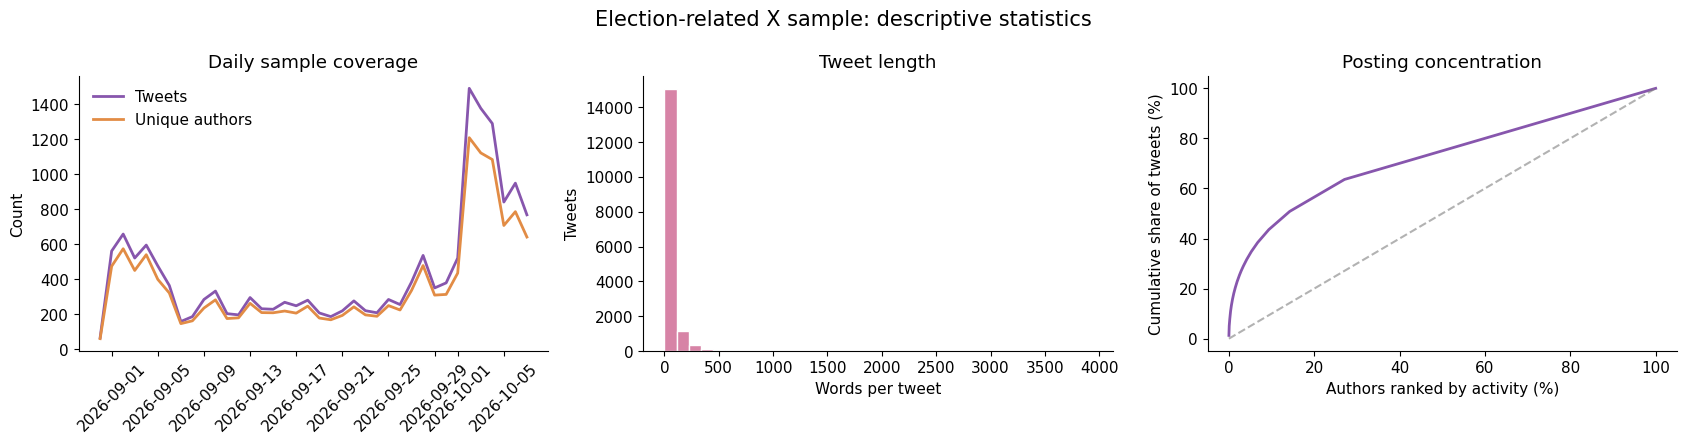

Saved report outputs to: /content/drive/MyDrive/midterm-tweets/report_outputs


In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

REPORT_DIR = FOLDER / "report_outputs"
REPORT_DIR.mkdir(exist_ok=True)

d = tweets.copy()
d["word_count"] = d["text"].str.split().str.len()
d["date_ny"] = pd.to_datetime(d["date_ny"])

# Include missing days explicitly.
days = pd.date_range(d["date_ny"].min(), d["date_ny"].max(), freq="D")
daily = (
    d.groupby("date_ny").size()
    .reindex(days, fill_value=0)
    .rename("tweets")
    .to_frame()
)

# Prefer author ID; fall back to username where needed.
author = pd.Series(pd.NA, index=d.index, dtype="string")
for col in ["author_id", "username"]:
    if col in d:
        values = d[col].astype("string").str.strip().replace("", pd.NA)
        author = author.fillna(values)

d["_author"] = author
author_counts = d["_author"].dropna().value_counts()

daily["unique_authors"] = (
    d.groupby("date_ny")["_author"].nunique()
    .reindex(days, fill_value=0)
)

known_author_tweets = author_counts.sum()
top10_share = (
    100 * author_counts.head(10).sum() / known_author_tweets
    if known_author_tweets else np.nan
)

stats = {
    "Unique tweets": len(d),
    "Start date (NYC)": days.min().date(),
    "End date (NYC)": days.max().date(),
    "Calendar days": len(days),
    "Days with tweets": int(daily["tweets"].gt(0).sum()),
    "Mean tweets per calendar day": round(daily["tweets"].mean(), 1),
    "Median tweets per calendar day": round(daily["tweets"].median(), 1),
    "Unique authors with identifiers": len(author_counts),
    "Tweets missing author identifiers (%)": round(100 * author.isna().mean(), 2),
    "Median words per tweet": round(d["word_count"].median(), 1),
    "Top 10 authors' share of identified tweets (%)": round(top10_share, 2),
}

if "language" in d:
    known_languages = d["language"].dropna()
    stats["English share of language-tagged tweets (%)"] = (
        round(100 * known_languages.eq("en").mean(), 2)
        if len(known_languages) else np.nan
    )

summary = pd.DataFrame(stats.items(), columns=["Statistic", "Value"])
display(summary)

plt.rcParams.update({
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

axes[0].plot(
    daily.index, daily["tweets"],
    color="#8756AD", linewidth=2, label="Tweets"
)
axes[0].plot(
    daily.index, daily["unique_authors"],
    color="#E28C45", linewidth=2, label="Unique authors"
)
axes[0].set_title("Daily sample coverage")
axes[0].set_ylabel("Count")
axes[0].tick_params(axis="x", rotation=45)
axes[0].legend(frameon=False)

axes[1].hist(d["word_count"], bins=35, color="#D783A6", edgecolor="white")
axes[1].set_title("Tweet length")
axes[1].set_xlabel("Words per tweet")
axes[1].set_ylabel("Tweets")

if len(author_counts):
    cumulative = author_counts.cumsum() / known_author_tweets * 100
    author_pct = np.arange(1, len(author_counts) + 1) / len(author_counts) * 100
    axes[2].plot(author_pct, cumulative, color="#8756AD", linewidth=2)
    axes[2].plot([0, 100], [0, 100], "--", color="gray", alpha=0.6)
    axes[2].set_title("Posting concentration")
    axes[2].set_xlabel("Authors ranked by activity (%)")
    axes[2].set_ylabel("Cumulative share of tweets (%)")
else:
    axes[2].text(
        0.5, 0.5, "Author identifiers unavailable",
        ha="center", va="center", transform=axes[2].transAxes
    )

fig.suptitle("Election-related X sample: descriptive statistics", fontsize=15)
fig.tight_layout()
fig.savefig(REPORT_DIR / "tweet_descriptive_charts.png", dpi=300, bbox_inches="tight")
plt.show()

summary.to_csv(REPORT_DIR / "tweet_summary_stats.csv", index=False)
daily.rename_axis("date_ny").to_csv(REPORT_DIR / "tweet_daily_coverage.csv")

print(f"Saved report outputs to: {REPORT_DIR}")

,Statistic,Value
0,Sampled headlines,2974
1,Start date (NYC),2026-09-08
2,End date (NYC),2026-10-08
3,Calendar days,31
4,Days with headlines,31
5,Unique outlets,1154
6,Mean headlines per calendar day,95.9
7,Median words per headline,12.0
8,Top 10 outlets' share of headlines (%),10.32


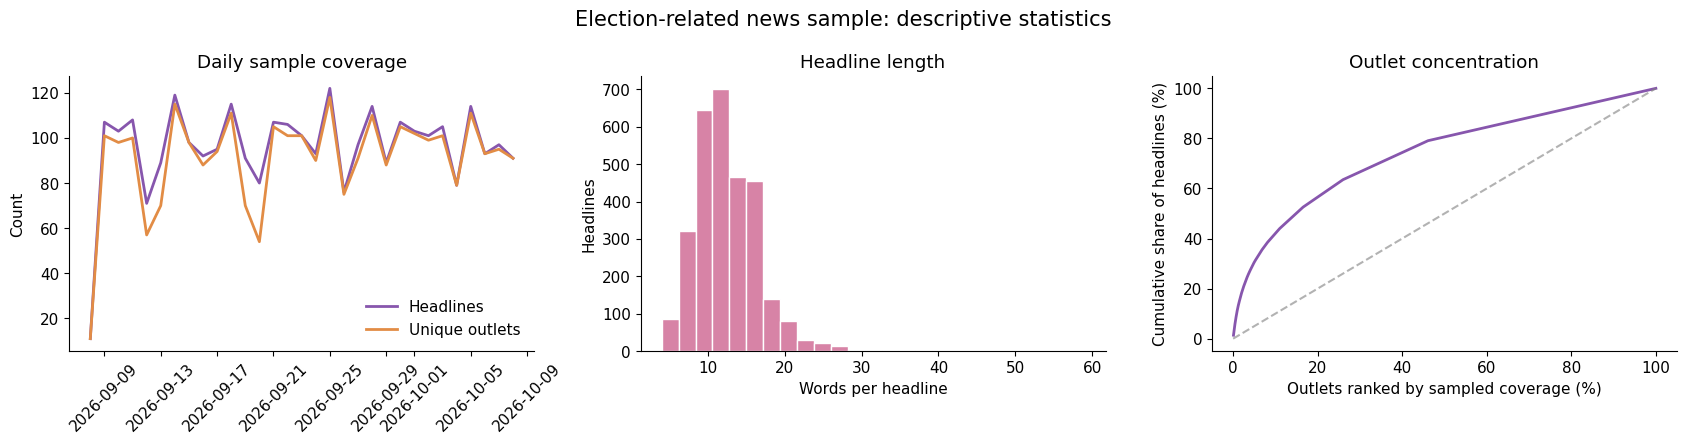

Saved report outputs to: /content/drive/MyDrive/midterm-tweets/report_outputs


In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Save alongside the tweet report outputs.
REPORT_DIR = FOLDER / "report_outputs"
REPORT_DIR.mkdir(exist_ok=True)

n = final_news.copy()
n["observed_at"] = pd.to_datetime(n["observed_at"], utc=True)
n["date_ny"] = (
    n["observed_at"].dt.tz_convert("America/New_York").dt.normalize()
)
n["word_count"] = n["headline"].fillna("").str.split().str.len()
n["outlet"] = n["outlet"].fillna("unknown")

days = pd.date_range(
    n["date_ny"].min(), n["date_ny"].max(), freq="D"
)
daily_news = pd.DataFrame(index=days)
daily_news["headlines"] = (
    n.groupby("date_ny").size().reindex(days, fill_value=0)
)
daily_news["unique_outlets"] = (
    n.groupby("date_ny")["outlet"].nunique()
    .reindex(days, fill_value=0)
)

outlet_counts = n["outlet"].value_counts()
top10_share = 100 * outlet_counts.head(10).sum() / len(n)

news_summary = pd.DataFrame({
    "Statistic": [
        "Sampled headlines",
        "Start date (NYC)",
        "End date (NYC)",
        "Calendar days",
        "Days with headlines",
        "Unique outlets",
        "Mean headlines per calendar day",
        "Median words per headline",
        "Top 10 outlets' share of headlines (%)",
    ],
    "Value": [
        len(n),
        days.min().date(),
        days.max().date(),
        len(days),
        int(daily_news["headlines"].gt(0).sum()),
        len(outlet_counts),
        round(daily_news["headlines"].mean(), 1),
        round(n["word_count"].median(), 1),
        round(top10_share, 2),
    ],
})
display(news_summary)

plt.rcParams.update({
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

axes[0].plot(
    daily_news.index, daily_news["headlines"],
    color="#8756AD", linewidth=2, label="Headlines"
)
axes[0].plot(
    daily_news.index, daily_news["unique_outlets"],
    color="#E28C45", linewidth=2, label="Unique outlets"
)
axes[0].set_title("Daily sample coverage")
axes[0].set_ylabel("Count")
axes[0].tick_params(axis="x", rotation=45)
axes[0].legend(frameon=False)

axes[1].hist(
    n["word_count"], bins=25,
    color="#D783A6", edgecolor="white"
)
axes[1].set_title("Headline length")
axes[1].set_xlabel("Words per headline")
axes[1].set_ylabel("Headlines")

outlet_pct = np.arange(1, len(outlet_counts) + 1) / len(outlet_counts) * 100
cumulative = outlet_counts.cumsum() / len(n) * 100
axes[2].plot(outlet_pct, cumulative, color="#8756AD", linewidth=2)
axes[2].plot([0, 100], [0, 100], "--", color="gray", alpha=0.6)
axes[2].set_title("Outlet concentration")
axes[2].set_xlabel("Outlets ranked by sampled coverage (%)")
axes[2].set_ylabel("Cumulative share of headlines (%)")

fig.suptitle(
    "Election-related news sample: descriptive statistics",
    fontsize=15
)
fig.tight_layout()
fig.savefig(
    REPORT_DIR / "news_descriptive_charts.png",
    dpi=300, bbox_inches="tight"
)
plt.show()

news_summary.to_csv(REPORT_DIR / "news_summary_stats.csv", index=False)
daily_news.rename_axis("date_ny").to_csv(
    REPORT_DIR / "news_daily_coverage.csv"
)

print(f"Saved report outputs to: {REPORT_DIR}")

In [21]:
!pip -q install bertopic sentence-transformers umap-learn hdbscan

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.7/154.7 kB 9.4 MB/s eta 0:00:00


In [11]:
import re
import numpy as np
import pandas as pd
import torch

def clean_topic_text(text):
    text = str(text)
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"(?<!\w)@\w+", " ", text)
    text = re.sub(r"^\s*RT\s*:?\s*", "", text)
    text = re.sub(r"#(\w+)", r"\1", text)
    return re.sub(r"\s+", " ", text).strip()

def prepare_documents(frame, text_column):
    result = frame.copy()
    result["original_text"] = result[text_column].fillna("")
    result["model_text"] = result["original_text"].map(clean_topic_text)

    result = result[
        result["model_text"].str.split().str.len().ge(4)
    ].copy()

    # Discover topics from unique wording so repeated posts do not
    # dominate clustering. Assign topics to all retained records later.
    documents = (
        result["model_text"]
        .drop_duplicates()
        .tolist()
    )
    return result.reset_index(drop=True), documents

tweet_topics_data, tweet_docs = prepare_documents(tweets, "text")
news_topics_data, news_docs = prepare_documents(final_news, "headline")

print(f"Tweets retained: {len(tweet_topics_data):,}")
print(f"Unique tweet texts for discovery: {len(tweet_docs):,}")
print(f"News headlines retained: {len(news_topics_data):,}")
print(f"Unique headlines for discovery: {len(news_docs):,}")
print("Device:", "GPU" if torch.cuda.is_available() else "CPU")

Tweets retained: 16,883
Unique tweet texts for discovery: 16,344
News headlines retained: 2,974
Unique headlines for discovery: 2,974
Device: CPU


In [22]:
from sentence_transformers import SentenceTransformer
from bertopic import BERTopic
from sklearn.feature_extraction.text import CountVectorizer
from umap import UMAP
from hdbscan import HDBSCAN

encoder = SentenceTransformer(
    "all-MiniLM-L6-v2",
    device="cuda" if torch.cuda.is_available() else "cpu",
)

def fit_topics(documents, min_cluster_size):
    if len(documents) < max(30, min_cluster_size * 2):
        raise ValueError("Too few documents for these clustering settings.")

    embeddings = encoder.encode(
        documents,
        batch_size=64,
        show_progress_bar=True,
        normalize_embeddings=True,
    )

    model = BERTopic(
        embedding_model=encoder,
        umap_model=UMAP(
            n_neighbors=15,
            n_components=5,
            min_dist=0.0,
            metric="cosine",
            random_state=42,
        ),
        hdbscan_model=HDBSCAN(
            min_cluster_size=min_cluster_size,
            min_samples=5,
            metric="euclidean",
            cluster_selection_method="eom",
            prediction_data=True,
        ),
        vectorizer_model=CountVectorizer(
            stop_words="english",
            ngram_range=(1, 2),
            min_df=2,
        ),
        top_n_words=10,
        calculate_probabilities=False,
        verbose=True,
    )

    labels, _ = model.fit_transform(documents, embeddings)

    return model, dict(zip(documents, labels))


news_model, news_lookup = fit_topics(
    news_docs, min_cluster_size=20
)

news_topics_data["topic_id"] = (
    news_topics_data["model_text"].map(news_lookup)
)

KeyboardInterrupt: 

In [15]:
TOPIC_DIR = FOLDER / "topic_outputs"
TOPIC_DIR.mkdir(exist_ok=True)

tweet_topics_data.to_csv(
    TOPIC_DIR / "tweets_with_topics.csv", index=False
)
news_topics_data.to_csv(
    TOPIC_DIR / "news_with_topics.csv", index=False
)
tweet_topic_summary.to_csv(
    TOPIC_DIR / "tweet_topic_review.csv", index=False
)
news_topic_summary.to_csv(
    TOPIC_DIR / "news_topic_review.csv", index=False
)
fig.savefig(
    TOPIC_DIR / "topic_shares.png",
    dpi=300, bbox_inches="tight"
)

# Save models for assigning topics to future records.
tweet_model.save(str(TOPIC_DIR / "tweet_bertopic"), serialization="pickle")
news_model.save(str(TOPIC_DIR / "news_bertopic"), serialization="pickle")

print(f"Saved to: {TOPIC_DIR}")

2026-10-10 00:54:07,807 - BERTopic - WARNING: When you use `pickle` to save/load a BERTopic model,please make sure that the environments in which you saveand load the model are **exactly** the same. The version of BERTopic,its dependencies, and python need to remain the same.
2026-10-10 00:54:45,110 - BERTopic - WARNING: When you use `pickle` to save/load a BERTopic model,please make sure that the environments in which you saveand load the model are **exactly** the same. The version of BERTopic,its dependencies, and python need to remain the same.


Saved to: /content/drive/MyDrive/midterm-tweets/topic_outputs


In [24]:
FOLDER = Path("/content/drive/MyDrive/midterm-tweets")
TOPIC_DIR = FOLDER / "topic_outputs"

tweet_topics_data = pd.read_csv(
    TOPIC_DIR / "tweets_with_topics.csv", index_col=0
)
news_topics_data = pd.read_csv(
    TOPIC_DIR / "news_with_topics.csv", index_col=0
)

In [25]:
import re
import numpy as np
import pandas as pd
import torch

from sentence_transformers import SentenceTransformer
from bertopic import BERTopic
from sklearn.feature_extraction.text import CountVectorizer
from umap import UMAP
from hdbscan import HDBSCAN

# --------------------------------------------------
# 1. Prepare modeling text
# --------------------------------------------------
def clean_topic_text(value):
    text = "" if pd.isna(value) else str(value)
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"(?<!\w)@\w+", " ", text)
    text = re.sub(r"^\s*RT\s*:?\s*", "", text)
    text = re.sub(r"#(\w+)", r"\1", text)
    return re.sub(r"\s+", " ", text).strip()

def prepare_data(frame):
    out = frame.copy().reset_index(drop=True)
    out["original_text"] = out["original_text"].fillna("")
    out["model_text"] = out["original_text"].map(clean_topic_text)
    return out[
        out["model_text"].str.split().str.len().ge(4)
    ].reset_index(drop=True)

# Preserve loaded records for auditing.
tweets_loaded = tweet_topics_data.copy()
news_loaded = news_topics_data.copy()

tw = prepare_data(tweets_loaded)
nw = prepare_data(news_loaded)

# --------------------------------------------------
# 2. Fast tweet-only relevance screen
# --------------------------------------------------
noise_pattern = (
    r"\b(?:BBNaija|Big Brother Naija|Peter Obi|Tinubu|"
    r"Kwankwaso|Lamine Yamal|Ballon d['’]?Or)\b"
)
us_pattern = (
    r"\b(?:midterms?|congress(?:ional)?|democrats?|"
    r"republicans?|GOP|Trump|Biden|Harris|White House|"
    r"Medicare|Medicaid|Obamacare|"
    r"US Senate|U\.S\. Senate|US House|U\.S\. House)\b"
)

noise = tw["original_text"].str.contains(
    noise_pattern, case=False, regex=True, na=False
)
us_context = tw["original_text"].str.contains(
    us_pattern, case=False, regex=True, na=False
)

tw["relevance_label"] = "unclear"
tw.loc[us_context, "relevance_label"] = "candidate_relevant"
tw.loc[noise & ~us_context, "relevance_label"] = "obvious_noise"
tw.loc[noise & us_context, "relevance_label"] = "unclear"

tweet_filter_audit = tw.copy()

# Retain unclear records; exclude only explicit noise.
tweets_for_topics = tw[
    tw["relevance_label"].ne("obvious_noise")
].copy().reset_index(drop=True)

print("Tweet screening:")
display(tweet_filter_audit["relevance_label"].value_counts())
print(f"Tweets retained: {len(tweets_for_topics):,}")
print(f"News retained without relevance filtering: {len(nw):,}")

# --------------------------------------------------
# 3. Define BERTopic fitting function
# --------------------------------------------------
encoder = SentenceTransformer(
    "all-MiniLM-L6-v2",
    device="cuda" if torch.cuda.is_available() else "cpu",
)

def fit_topics(documents, min_cluster_size):
    if len(documents) < max(30, 2 * min_cluster_size):
        raise ValueError("Too few unique texts for these cluster settings.")

    embeddings = encoder.encode(
        documents,
        batch_size=64,
        show_progress_bar=True,
        normalize_embeddings=True,
    )

    model = BERTopic(
        embedding_model=encoder,
        umap_model=UMAP(
            n_neighbors=15,
            n_components=5,
            min_dist=0.0,
            metric="cosine",
            random_state=42,
        ),
        hdbscan_model=HDBSCAN(
            min_cluster_size=min_cluster_size,
            min_samples=5,
            metric="euclidean",
            cluster_selection_method="eom",
            prediction_data=True,
        ),
        vectorizer_model=CountVectorizer(
            stop_words="english",
            ngram_range=(1, 2),
            min_df=2,
        ),
        top_n_words=10,
        calculate_probabilities=False,
        verbose=True,
    )

    labels, _ = model.fit_transform(documents, embeddings)
    return model, dict(zip(documents, labels))

# --------------------------------------------------
# 4. Refit both source-specific models
# --------------------------------------------------
tweet_topics_data = tweets_for_topics.copy()
news_topics_data = nw.copy()

# Discover clusters using unique texts, then map to all records.
tweet_docs = tweet_topics_data["model_text"].drop_duplicates().tolist()
news_docs = news_topics_data["model_text"].drop_duplicates().tolist()

print("\nFitting filtered tweets...")
tweet_model, tweet_lookup = fit_topics(
    tweet_docs, min_cluster_size=50
)

print("\nFitting news headlines...")
news_model, news_lookup = fit_topics(
    news_docs, min_cluster_size=20
)

tweet_topics_data["topic_id"] = (
    tweet_topics_data["model_text"].map(tweet_lookup).astype(int)
)
news_topics_data["topic_id"] = (
    news_topics_data["model_text"].map(news_lookup).astype(int)
)

# --------------------------------------------------
# 5. Review tables
# --------------------------------------------------
def topic_review_table(model, data):
    rows = []

    for topic_id, group in data.groupby("topic_id"):
        topic_id = int(topic_id)
        rows.append({
            "topic_id": topic_id,
            "record_count": len(group),
            "share_pct": round(100 * len(group) / len(data), 2),
            "keywords": (
                ", ".join(word for word, _ in model.get_topic(topic_id))
                if topic_id != -1 else "Unassigned / outlier"
            ),
            "representative_examples": (
                (model.get_representative_docs(topic_id) or [])[:3]
                if topic_id != -1 else []
            ),
            "random_examples": (
                group["original_text"]
                .sample(min(3, len(group)), random_state=42)
                .tolist()
            ),
        })

    return pd.DataFrame(rows).sort_values(
        "record_count", ascending=False
    ).reset_index(drop=True)

tweet_topic_summary = topic_review_table(tweet_model, tweet_topics_data)
news_topic_summary = topic_review_table(news_model, news_topics_data)

for name, data, summary in [
    ("Tweets", tweet_topics_data, tweet_topic_summary),
    ("News", news_topics_data, news_topic_summary),
]:
    print(
        f"\n{name}: "
        f"{data.loc[data.topic_id.ne(-1), 'topic_id'].nunique()} topics; "
        f"{100 * data.topic_id.eq(-1).mean():.1f}% unassigned"
    )
    display(summary)

Tweet screening:


,count
relevance_label,
candidate_relevant,11876
unclear,4660
obvious_noise,347


Tweets retained: 16,536
News retained without relevance filtering: 2,974


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

...

2026-10-10 23:46:31,257 - BERTopic - Dimensionality - Fitting the dimensionality reduction algorithm
2026-10-10 23:46:55,029 - BERTopic - Dimensionality - Completed ✓
2026-10-10 23:46:55,032 - BERTopic - Cluster - Start clustering the reduced embeddings
2026-10-10 23:46:55,195 - BERTopic - Cluster - Completed ✓
2026-10-10 23:46:55,200 - BERTopic - Representation - Fine-tuning topics using representation models.
2026-10-10 23:46:55,365 - BERTopic - Representation - Completed ✓



Tweets: 73 topics; 25.6% unassigned


,topic_id,record_count,share_pct,keywords,representative_examples,random_examples
0,-1,4225,25.55,Unassigned / outlier,[],[🚨Hakeem Jeffries has proven that he can’t be ...
1,0,1043,6.31,"vote democrat, vote republican, vote, democrat...","[This👇👇 I will never vote Democrat, This is wh...","[If you LOVE America, you will vote Republican..."
2,1,808,4.89,"michigan, sayed, el sayed, el, abdul, abdul el...",[NEW QUANTUS INSIGHTS MICHIGAN POLL | October ...,[Black Michiganders feel abandoned by Abdul El...
3,2,636,3.85,"iran, war, irgc, trump, iranian, midterms, dea...",[Iran is beginning to punch a little too above...,[Iran wrote a letter to Americans asking them ...
4,3,478,2.89,"000, dividend, checks, adult, trump, republica...",[🔥🚨 IT'S OFFICIAL — President Trump CONFIRMS $...,[Inflating away the debt is the oldest trick i...
...,...,...,...,...,...,...
69,67,59,0.36,"cornell, sex, women, doe, transgender, cornell...",['Radical' Far left' ‘Extreme' 'out of touch’:...,[@SaraHermanw0 Always Vote Republican Dont lis...
70,68,57,0.34,"johnson, impeached, mike johnson, mike, speake...",[WATCH 🚨: Jesse Watters: “If Democrats do win ...,[Marco Rubio realizing the Democrats will win ...
71,70,51,0.31,"nz, zealand, new zealand, labor, meter, bribe ...",[🚩John Key just keeps digging - makes absurd c...,[Te Pāti Māori list out today. Only one person...
72,71,51,0.31,"osun, vote, 2028, grateful, doors, need, vote ...",[I'm honored to have the support of Merced Cou...,"[Good morning, my friends! We had our 1st Pebb..."



News: 44 topics; 20.9% unassigned


,topic_id,record_count,share_pct,keywords,representative_examples,random_examples
0,-1,622,20.91,Unassigned / outlier,[],[They Trained to Watch ICE. Now They're Preppi...
1,0,219,7.36,"republicans, trump, gop, democrats, midterms, ...",[Republicans distance from Trump ahead of midt...,[The Morning Briefing: Dems' Virulent Antisemi...
2,1,201,6.76,"iran, war, iran war, end, strikes, deal, trump...",[Trump predicts Iran War will end 'immediately...,[Trump faces tough choices as Iran dangles dea...
3,2,113,3.80,"000, checks, promises, republicans win, trump ...","[Trump promises $5,000 checks if Republicans w...",[Congressional Staff Planned Expensive Europea...
4,3,96,3.23,"senate, senate race, race, minnesota, kansas, ...",[Michele Tafoya Is Giving Democrats Nightmares...,[Political ads flood Kansas as Senate race dra...
5,4,87,2.93,"vor, den, für, den midterms, die, trumps, der,...",[Vor den Midterms: Wegen Hegseth? US-Repräsent...,[Midterm-Wahlen in den USA: Sie finden den Sch...
6,5,85,2.86,"rally, president, midterm rally, president tru...",[President Trump to host midterm campaign rall...,[Trump's Vandalia Rally brings political activ...
7,6,81,2.72,"convention, midterm convention, republican mid...",[5 lessons from the Republican midterm convent...,[FACT FOCUS: A look at false and misleading cl...
8,7,76,2.56,"voting, early, early voting, begins, voting be...",[Early voting begins in US midterm that could ...,[5 things to know about voting in Nevada's 202...
9,8,70,2.35,"di, il, le, elezioni, la, di midterm, elezioni...",[«Andate a votare e glielo mettiamo nel c...»:...,[L'inflazione non è l'unica incognita che inco...


In [26]:
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.decomposition import NMF, LatentDirichletAllocation

N_TOPICS = 10
topic_results = {}

def fit_nmf_lda(data, source, n_topics=10):
    frame = data.copy().reset_index(drop=True)
    docs = frame["model_text"].drop_duplicates().tolist()

    settings = dict(
        stop_words="english",
        ngram_range=(1, 2),
        min_df=2,
        max_df=0.95,
        max_features=10000,
    )

    tfidf = TfidfVectorizer(**settings)
    counts = CountVectorizer(**settings)

    X_nmf = tfidf.fit_transform(docs)
    X_lda = counts.fit_transform(docs)

    if n_topics > min(X_nmf.shape):
        raise ValueError(f"{source}: reduce N_TOPICS.")

    models = [
        (
            "NMF",
            NMF(
                n_components=n_topics,
                init="nndsvda",
                max_iter=500,
                random_state=42,
            ),
            tfidf,
            X_nmf,
        ),
        (
            "LDA",
            LatentDirichletAllocation(
                n_components=n_topics,
                learning_method="online",
                batch_size=256,
                max_iter=10,
                random_state=42,
                n_jobs=2,
            ),
            counts,
            X_lda,
        ),
    ]

    for method, model, vectorizer, X_train in models:
        print(f"\nFitting {source} — {method}...")
        model.fit(X_train)

        X_all = vectorizer.transform(frame["model_text"])
        valid = np.asarray(X_all.sum(axis=1)).ravel() > 0
        weights = model.transform(X_all)

        if method == "NMF":
            # Compensate for component scaling before normalizing.
            weights *= model.components_.sum(axis=1)[None, :]

        totals = weights.sum(axis=1, keepdims=True)
        valid &= totals.ravel() > 0

        weights = np.divide(
            weights, totals,
            out=np.zeros_like(weights),
            where=totals > 0,
        )
        weights[~valid] = np.nan

        dominant = np.full(len(frame), -1, dtype=int)
        dominant[valid] = weights[valid].argmax(axis=1)

        scored = frame.copy()
        scored["bertopic_topic_id"] = scored["topic_id"]
        scored["topic_id"] = dominant
        scored["topic_method"] = method
        scored["has_topic_signal"] = valid

        for k in range(n_topics):
            scored[f"topic_weight_{k}"] = weights[:, k]

        # Build review table using keywords and original texts.
        terms = vectorizer.get_feature_names_out()
        valid_indices = np.flatnonzero(valid)
        rows = []

        for k, component in enumerate(model.components_):
            top_terms = terms[np.argsort(component)[-10:][::-1]]
            group = scored[scored["topic_id"].eq(k)]

            ranked = valid_indices[
                np.argsort(weights[valid_indices, k])[::-1]
            ]
            ranked = ranked[weights[ranked, k] > 0]

            rows.append({
                "topic_id": k,
                "record_count": len(group),
                "share_pct": round(100 * len(group) / len(scored), 2),
                "mean_topic_weight_pct": (
                    round(100 * weights[valid, k].mean(), 2)
                    if valid.any() else np.nan
                ),
                "keywords": ", ".join(top_terms),
                "representative_examples": (
                    scored.iloc[ranked]
                    .drop_duplicates("model_text")
                    ["original_text"].head(3).tolist()
                ),
                "random_examples": (
                    group["original_text"]
                    .sample(min(3, len(group)), random_state=42)
                    .tolist()
                ),
            })

        summary = (
            pd.DataFrame(rows)
            .sort_values("record_count", ascending=False)
            .reset_index(drop=True)
        )

        topic_results[(source, method)] = {
            "model": model,
            "vectorizer": vectorizer,
            "data": scored,
            "weights": weights,
            "summary": summary,
        }

        print(
            f"{len(scored):,} records; "
            f"{100 * (~valid).mean():.2f}% without topic signal"
        )
        display(summary)

fit_nmf_lda(tweet_topics_data, "Tweets", N_TOPICS)
fit_nmf_lda(news_topics_data, "News", N_TOPICS)


Fitting Tweets — NMF...
16,536 records; 0.01% without topic signal


,topic_id,record_count,share_pct,mean_topic_weight_pct,keywords,representative_examples,random_examples
0,9,6237,37.72,33.09,"vote, people, don, like, want, democrats, just...","[""It’s apparent that Howard has strong organiz...","[20,267 Washington Ballots Tossed. But Don’t A..."
1,5,3600,21.77,21.46,"trump, midterms, president, republicans, win, ...","[Gloves are coming off after the midterms., Tr...",[Unbelievable. Trump literally just told North...
2,1,1764,10.67,10.52,"race, senate, senate race, kansas, house, hous...","[Bolts Magazine: David Leslie (D), the 4th pla...",[🚨Just in: The Senate Leadership Fund is pulli...
3,7,1306,7.90,9.26,"2026, 2026 election, election, november 2026, ...",[2026 Election: Irvine’s Measure D would chang...,[Election Fraud is now underway for 2026 elect...
4,2,1073,6.49,6.65,"midterm, midterm election, election, 2026 midt...","[""Fearing a midterm election cheating..."" Ther...",[Do you plan to vote in the midterm election t...
5,0,738,4.46,6.75,"vote republican, republican, vote, november, r...",[“Monorails for all cities that vote Republica...,"[If you love pedophilia coverups, war, high in..."
6,8,692,4.18,3.77,"texas, talarico, paxton, texas senate, ken, ke...",[TEXAS SENATE RACE: Harvard-educated James Tal...,[TEXAS SENATE RACE: James Talarico (CIS) uses ...
7,4,521,3.15,4.64,"vote democrat, democrat, vote, america, death ...",[@overton_news How do you vote Democrat after ...,[This isn’t a surprise… what’s surprising are ...
8,6,372,2.25,2.27,"sayed, el, el sayed, michigan, abdul, abdul el...",[Mike Rogers calls El-Sayed a 'con man' over S...,[A lifelong Democrat in Michigan says she may ...
9,3,232,1.40,1.59,"ariasbts, aria, vote ariasbts, awards, 2026 ar...",[I vote for #ARIASBTS at the 2026 ARIA Music A...,[I vote for #ARIASBTS at the 2026 ARIA Music A...



Fitting Tweets — LDA...
16,536 records; 0.01% without topic signal


,topic_id,record_count,share_pct,mean_topic_weight_pct,keywords,representative_examples,random_examples
0,2,4786,28.94,22.57,"vote, republican, vote republican, democrat, d...","[VOTING COLLAB - Day 1 GLLIT, we have a voting...","[If you vote democrat, you need a mental evalu..."
1,6,2090,12.64,12.15,"people, michigan, like, party, vote, el, sayed...",[🚨Tucker Carlson basically endorses Abdul El-S...,[Journalists that will vote for Messi looking ...
2,7,1969,11.91,9.99,"senate, race, senate race, texas, paxton, tala...",[🚨BREAKING: Ken Paxton maintains his lead on h...,[🚨 JUST IN: North Carolina crowd just ERUPTED ...
3,9,1871,11.31,11.12,"election, midterm, 2026, midterm election, 202...",[🚨 THE S&P 500 HAS NEVER ESCAPED THIS MIDTERM ...,[With less than a month until the midterm elec...
4,3,1565,9.46,9.83,"trump, president, midterms, president trump, r...","[BREAKING: President Trump says $5,000 ""Trump ...","[🚨 WOW! President Trump just confirmed the $5,..."
5,4,1252,7.57,8.69,"midterms, democrats, trump, iran, going, repub...","[Gas prices are high right now, and the highes...","[The terrorist regime that chants ""Death to Am..."
6,0,1183,7.15,8.57,"state, court, federal, mail, voting, ballot, l...",[The Trump administration pushed back on a fed...,[Arizona’s Groundwater Fight Moves From Desert...
7,1,986,5.96,7.23,"voters, house, election, 2026, 26, 25, polling...","[🗳️🇺🇸 RISD, are you registered to vote? The vo...",[📅 Three days remain until the voter registrat...
8,5,475,2.87,5.33,"year, market, ai, vance, years, care, economy,...",[My prediction. - Fed holds - Anthropic S-1 le...,[Just because we're bombarded with irrational ...
9,8,358,2.16,4.51,"israel, death, jewish, biden, amp, obama, epst...",[I have undertaken this project to put a face ...,[I have a hunch the next Democrat president wi...



Fitting News — NMF...
2,974 records; 0.10% without topic signal


,topic_id,record_count,share_pct,mean_topic_weight_pct,keywords,representative_examples,random_examples
0,1,640,21.52,19.90,"midterms, 2026, 2026 midterms, democrats, vote...","[Oh, So This is the Admin Doing Its Best to ST...",[Normally Podcast: Democrats Are Back: Why Rep...
1,9,582,19.57,19.88,"trump, midterm, donald, donald trump, republic...",[Donald Trump: మధ్యంతర ఎన్నికల వరకు యుద్ధం కొన...,[عاجل. - واشنطن ترفع جاهزيتها لضربات مكثّفة مح...
2,2,370,12.44,12.78,"senate, race, senate race, texas, texas senate...","[Notes on the Florida Senate Race, DAVID MARCU...","[Meet Julia Letlow, Republican for U.S. Senate..."
3,8,267,8.98,9.15,"house, races, house races, republicans, money,...",[Defra brings livestock traceability developme...,[Vice President JD Vance campaigns in Council ...
4,0,263,8.84,8.75,"elections, midterm elections, midterm, 2026, 2...",[US job growth slows as unemployment rises bef...,[Trained to Protect Immigrants From ICE. Now t...
5,5,232,7.80,7.83,"election, midterm election, midterm, 2026, 202...","['A Republic, if you can keep it': We served p...",[Risch campaign says rumors of using 1917 Idah...
6,3,193,6.49,7.41,"convention, midterm convention, gop, midterm, ...",[Fetterman Goes Full Zell Miller At GOP Midter...,[John Fetterman to Address GOP Midterm Convent...
7,4,180,6.05,5.53,"iran, war, iran war, says, trump says, trump, ...",[Pete Hegseth could be IMPEACHED over scandals...,"[Live Updates: Trump predicts the war to end ""..."
8,7,164,5.51,5.72,"ahead, ahead midterms, midterms, approval, pol...",[Poll Shows Trump's Approval Rating Hits Low A...,[Trump Plans To Ease Off-Road Diesel Restricti...
9,6,80,2.69,3.05,"court, supreme, supreme court, mail, trump mai...",[Clearfield officials discuss Supreme Court de...,[The Supreme Court won't allow midterm mail-in...



Fitting News — LDA...
2,974 records; 0.10% without topic signal


,topic_id,record_count,share_pct,mean_topic_weight_pct,keywords,representative_examples,random_examples
0,0,611,20.54,18.76,"midterm, trump, gop, election, convention, mid...",[Trump implores Republican convention goers to...,"[Cooper defends record as Trump, Whatley hamme..."
1,9,422,14.19,13.46,"senate, race, senate race, races, house, poll,...",[Republicans pour money into dozens of US Hous...,[National Democrats invest in 2 Iowa Senate el...
2,5,376,12.64,12.00,"midterms, trump, 2026, republicans, voters, la...",[Cuándo son las elecciones de Estados Unidos 2...,[Trump campaigns in deep red Alabama as midter...
3,8,352,11.84,12.05,"midterms, ahead, trump, ahead midterms, electi...",[Fact-check: Cooper says NC officials 'removed...,"[Fight, fight, fight: Team Trump mounts all-ou..."
4,3,276,9.28,9.27,"iran, trump, midterm, elections, midterm elect...","[Trump respinge il piano dell'Iran, «no» alla ...","[Inflation and the midterm elections, Expert d..."
5,4,241,8.10,8.80,"midterms, trump, midterm, says, prices, electi...",[One year today: Charlie Kirk's absence seen i...,[Trump says oil and gas prices won't fall unti...
6,7,206,6.93,7.52,"race, senate, senate race, news, ohio, carolin...",[Darline Graham agrees to debate Democratic ch...,[Trump takes center stage at Republicans' firs...
7,1,182,6.12,7.14,"midterms, voter, election, november, 2026, bal...",[State error in Texas creates huge backlog in ...,[$4.5M Campaign Launches To Boost Black Voter ...
8,6,157,5.28,6.09,"midterms, vance, midterm, trump, red, jd, jd v...",[This swing state Republican keeps distancing ...,[मध्यावधि चुनावपछि इरानमाथि फेरि आक्रमण हुन सक...
9,2,148,4.98,4.92,"midterms, trump, vor, den, für, die, den midte...",[Wahlkampf-Events: Gut einen Monat vor Midterm...,"[Dennis Hastert, disgraced former House speake..."


In [27]:
from pathlib import Path
import json
import pandas as pd

OUTPUT_DIR = Path(FOLDER) / "topic_outputs" / "refitted_reviews"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

reviews = {
    "Tweets_BERTopic": tweet_topic_summary,
    "News_BERTopic": news_topic_summary,
    "Tweets_NMF": topic_results[("Tweets", "NMF")]["summary"],
    "News_NMF": topic_results[("News", "NMF")]["summary"],
    "Tweets_LDA": topic_results[("Tweets", "LDA")]["summary"],
    "News_LDA": topic_results[("News", "LDA")]["summary"],
}

# Convert example lists to readable text; add columns for our annotations.
def prepare_review(table):
    out = table.copy()

    for column in ["representative_examples", "random_examples"]:
        if column in out:
            out[column] = out[column].map(
                lambda examples: "\n\n".join(
                    f"{i}. {text}" for i, text in enumerate(examples, 1)
                ) if isinstance(examples, list) else str(examples)
            )

    out["issue_label"] = ""
    out["category"] = ""  # policy / campaign-polling / irrelevant / mixed
    out["review_notes"] = ""
    return out

prepared = {
    name: prepare_review(table) for name, table in reviews.items()
}

# CSVs preserve complete example text.
for name, table in prepared.items():
    table.to_csv(OUTPUT_DIR / f"{name}_review.csv", index=False)

# One combined CSV is also easy to upload.
combined = pd.concat(
    [
        table.assign(
            source=name.split("_")[0],
            method=name.split("_")[1],
        )
        for name, table in prepared.items()
    ],
    ignore_index=True,
)
combined.to_csv(OUTPUT_DIR / "all_topic_reviews.csv", index=False)

# Excel cells have a text-length limit; CSVs above retain full text.
workbook_path = OUTPUT_DIR / "all_topic_reviews.xlsx"
try:
    with pd.ExcelWriter(workbook_path, engine="openpyxl") as writer:
        for name, table in prepared.items():
            excel_table = table.copy()
            for column in excel_table.select_dtypes(include="object"):
                excel_table[column] = excel_table[column].map(
                    lambda value: value[:32000]
                    if isinstance(value, str) else value
                )
            excel_table.to_excel(writer, sheet_name=name, index=False)

    print("Workbook:", workbook_path)
except ImportError:
    print("Excel export needs openpyxl; the CSVs were saved successfully.")

print("Combined review CSV:", OUTPUT_DIR / "all_topic_reviews.csv")

Workbook: /content/drive/MyDrive/midterm-tweets/topic_outputs/refitted_reviews/all_topic_reviews.xlsx
Combined review CSV: /content/drive/MyDrive/midterm-tweets/topic_outputs/refitted_reviews/all_topic_reviews.csv


In [41]:
import pandas as pd

TWEET_ISSUES = {
    2: "Iran war",
    6: "Fuel prices",
    60: "Economy and jobs",
    8: "Immigration and enforcement",
    69: "Immigration and enforcement",
    23: "Healthcare, benefits and affordability (mixed)",
}

NEWS_ISSUES = {
    1: "Iran war",
    37: "Fuel prices",
    30: "Economy and jobs",
    38: "Healthcare, benefits and affordability (mixed)",
    16: "AI policy and data centers",
    18: "AI policy and data centers",
}

ISSUES = list(dict.fromkeys([
    *TWEET_ISSUES.values(),
    *NEWS_ISSUES.values(),
]))

def select_issue_documents(data, mapping, source, timestamp_col):
    out = data.copy()
    out["issue"] = out["topic_id"].map(mapping)
    out = out[out["issue"].notna()].copy()

    out["source"] = source
    out["timestamp"] = pd.to_datetime(
        out[timestamp_col], utc=True, errors="coerce"
    )

    print(
        f"{source}: {len(out):,} selected records; "
        f"{out['timestamp'].isna().sum():,} missing timestamps"
    )

    out = out.dropna(subset=["timestamp"])
    out["date_ny"] = (
        out["timestamp"]
        .dt.tz_convert("America/New_York")
        .dt.tz_localize(None)
        .dt.normalize()
    )
    return out

sentiment_documents = pd.concat([
    select_issue_documents(
        tweet_topics_data, TWEET_ISSUES, "Tweets", "created_at"
    ),
    select_issue_documents(
        news_topics_data, NEWS_ISSUES, "News", "observed_at"
    ),
], ignore_index=True)

display(
    sentiment_documents.groupby(["source", "issue"])
    .size()
    .unstack("source", fill_value=0)
    .rename_axis("Issue")
)

Tweets: 1,530 selected records; 0 missing timestamps
News: 377 selected records; 0 missing timestamps


source,News,Tweets
Issue,,
AI policy and data centers,87,0
Economy and jobs,33,72
Fuel prices,28,338
"Healthcare, benefits and affordability (mixed)",28,151
Immigration and enforcement,0,333
Iran war,201,636


In [44]:
import html
import numpy as np
import pandas as pd
from pathlib import Path
from google.cloud import bigquery

client = bigquery.Client(
    project="idyllic-mantis-498400-b1",
    location="US",
)

START_DATE = "2026-09-09"
END_DATE_EXCLUSIVE = "2026-10-09"
MAX_BYTES_BILLED = 30 * 1024**3
HEADLINES_PER_ISSUE_DAY = 15

# Headline matching rules: inspect the sampled examples before scoring.
ISSUE_PATTERNS = {
    "Iran war": (
        r"\biran\b|\biranian\b"
    ),
    "Fuel prices": (
        r"\b(gasoline|petrol|diesel)\b|"
        r"\b(gas|fuel|oil|energy|pump)\s+prices?\b|"
        r"\bprices?\s+(of|for)\s+(gas|fuel|oil|energy)\b|"
        r"\bat the pump\b"
    ),
    "Economy and jobs": (
        r"\b(inflation|affordability|unemployment|"
        r"job market|cost of living|economic policy)\b|"
        r"\b(economy|jobs|wages|employment)\b"
    ),
    "Immigration and enforcement": (
        r"\b(immigration|immigrants?|migrants?|"
        r"deportations?|asylum|border security|"
        r"border patrol|immigration enforcement)\b|"
        r"\bICE\b"
    ),
    "Healthcare, benefits and affordability (mixed)": (
        r"\b(healthcare|health care|medicare|medicaid|"
        r"obamacare|affordable care act|health insurance|"
        r"prescription drugs?|drug prices?|"
        r"social security|SNAP|food stamps)\b"
    ),
    "AI policy and data centers": (
        r"\b(artificial intelligence|generative AI|"
        r"AI policy|AI regulation|AI safety|"
        r"data cent(?:er|re)s?)\b"
    ),
}

# US context can appear in the headline OR GDELT's location metadata.
# This is a relevance screen, not proof that an article concerns voters.
US_CONTEXT_PATTERN = (
    r"\b(united states|u\.s\.|usa|american|"
    r"trump|white house|congress|congressional|"
    r"republicans?|democrats?|GOP|midterms?|"
    r"medicare|medicaid|obamacare|"
    r"federal reserve)\b|"
    r"\b(alabama|alaska|arizona|arkansas|california|"
    r"colorado|connecticut|delaware|florida|georgia|"
    r"hawaii|idaho|illinois|indiana|iowa|kansas|"
    r"kentucky|louisiana|maine|maryland|massachusetts|"
    r"michigan|minnesota|mississippi|missouri|montana|"
    r"nebraska|nevada|new hampshire|new jersey|"
    r"new mexico|new york|north carolina|north dakota|"
    r"ohio|oklahoma|oregon|pennsylvania|rhode island|"
    r"south carolina|south dakota|tennessee|texas|"
    r"utah|vermont|virginia|washington|"
    r"west virginia|wisconsin|wyoming)\b"
)

all_issue_pattern = "|".join(
    f"(?:{pattern})" for pattern in ISSUE_PATTERNS.values()
)

sql = r"""
WITH candidates AS (
  SELECT
    SAFE.PARSE_TIMESTAMP('%Y%m%d%H%M%S', CAST(`DATE` AS STRING))
      AS observed_at,
    SourceCommonName AS outlet,
    DocumentIdentifier AS url,
    REGEXP_EXTRACT(
      Extras, r'<PAGE_TITLE>([^<]*)</PAGE_TITLE>'
    ) AS headline,
    V2Themes AS themes,
    V2Locations AS locations,
    V2Tone AS gdelt_tone_raw
  FROM `gdelt-bq.gdeltv2.gkg_partitioned`
  WHERE _PARTITIONTIME >= TIMESTAMP(@start_date)
    AND _PARTITIONTIME < TIMESTAMP(@end_date)
    AND STARTS_WITH(DocumentIdentifier, 'http')
)
SELECT *
FROM candidates
WHERE observed_at IS NOT NULL
  AND REGEXP_CONTAINS(
    COALESCE(headline, ''),
    CONCAT('(?i)', @issue_pattern)
  )
  AND (
    REGEXP_CONTAINS(
      COALESCE(headline, ''),
      CONCAT('(?i)', @us_pattern)
    )
    OR REGEXP_CONTAINS(
      COALESCE(locations, ''),
      r'(?i)(^|;)[^;]*#US#'
    )
  )
QUALIFY ROW_NUMBER() OVER (
  PARTITION BY url ORDER BY observed_at
) = 1
"""

params = [
    bigquery.ScalarQueryParameter("start_date", "STRING", START_DATE),
    bigquery.ScalarQueryParameter(
        "end_date", "STRING", END_DATE_EXCLUSIVE
    ),
    bigquery.ScalarQueryParameter(
        "issue_pattern", "STRING", all_issue_pattern
    ),
    bigquery.ScalarQueryParameter(
        "us_pattern", "STRING", US_CONTEXT_PATTERN
    ),
]

dry = client.query(
    sql,
    job_config=bigquery.QueryJobConfig(
        query_parameters=params,
        dry_run=True,
        use_query_cache=False,
    ),
)
print(f"Estimated scan: {dry.total_bytes_processed / 1024**3:.2f} GiB")

if dry.total_bytes_processed > MAX_BYTES_BILLED:
    raise RuntimeError("Estimated scan exceeds the 30 GiB ceiling.")

# New variable names preserve the original election-news dataset.
issue_news_candidates = client.query(
    sql,
    job_config=bigquery.QueryJobConfig(
        query_parameters=params,
        maximum_bytes_billed=MAX_BYTES_BILLED,
    ),
).result().to_dataframe(create_bqstorage_client=False)

issue_news_candidates["headline"] = (
    issue_news_candidates["headline"]
    .fillna("")
    .map(html.unescape)
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)
issue_news_candidates["observed_at"] = pd.to_datetime(
    issue_news_candidates["observed_at"], utc=True, errors="coerce"
)

def parse_themes(value):
    if not isinstance(value, str):
        return []
    return sorted({
        entry.split(",")[0].strip()
        for entry in value.split(";")
        if entry.split(",")[0].strip()
    })

issue_news_candidates["theme_labels"] = (
    issue_news_candidates["themes"].map(parse_themes)
)
issue_news_candidates["_headline_key"] = (
    issue_news_candidates["headline"].str.casefold()
)

pool = (
    issue_news_candidates.loc[
        issue_news_candidates["headline"].str.split().str.len().ge(4)
        & issue_news_candidates["observed_at"].notna()
    ]
    .sort_values("observed_at")
    .drop_duplicates("_headline_key")
    .copy()
)

# Assign multiple issues where appropriate.
pool["issue_tags"] = [
    [
        issue
        for issue, pattern in ISSUE_PATTERNS.items()
        if pd.Series([headline]).str.contains(
            pattern, case=False, regex=True
        ).iloc[0]
    ]
    for headline in pool["headline"]
]
pool = pool.loc[pool["issue_tags"].map(bool)].copy()

pool["date_ny"] = (
    pool["observed_at"]
    .dt.tz_convert("America/New_York")
    .dt.tz_localize(None)
    .dt.normalize()
)
pool["outlet"] = pool["outlet"].fillna("unknown")

# Remove partial New York boundary days created by UTC query boundaries.
timestamp_start = pd.Timestamp(START_DATE, tz="America/New_York")
timestamp_end = pd.Timestamp(
    END_DATE_EXCLUSIVE, tz="America/New_York"
)
utc_query_end = pd.Timestamp(END_DATE_EXCLUSIVE, tz="UTC")

# Only include fully covered NY calendar days.
complete_end = (
    utc_query_end.tz_convert("America/New_York").normalize()
    .tz_localize(None)
)
pool = pool.loc[
    pool["date_ny"].ge(timestamp_start.tz_localize(None))
    & pool["date_ny"].lt(complete_end)
].copy()

tagged_pool = (
    pool.explode("issue_tags")
    .rename(columns={"issue_tags": "issue"})
)

# Random selection in rounds across outlets, separately per issue/day.
rng = np.random.default_rng(42)
tagged_pool["_random"] = rng.random(len(tagged_pool))
tagged_pool = tagged_pool.sort_values("_random")
tagged_pool["_outlet_round"] = tagged_pool.groupby(
    ["issue", "date_ny", "outlet"]
).cumcount()

issue_news_sample = (
    tagged_pool
    .sort_values(["issue", "date_ny", "_outlet_round", "_random"])
    .groupby(["issue", "date_ny"], group_keys=False)
    .head(HEADLINES_PER_ISSUE_DAY)
    .drop(columns=["_random", "_outlet_round", "_headline_key"])
    .reset_index(drop=True)
)

issue_news_sample["original_text"] = issue_news_sample["headline"]
issue_news_sample["text_source"] = "headline"
issue_news_sample["source"] = "News"
issue_news_sample["collection_method"] = "issue_targeted_supplement"

# Unique headlines can be scored once and merged back by URL.
issue_news_unique = (
    issue_news_sample
    .drop_duplicates("url")
    .drop(columns="issue")
    .reset_index(drop=True)
)

coverage = (
    issue_news_sample.groupby("issue")
    .agg(
        selected_headlines=("url", "size"),
        days_covered=("date_ny", "nunique"),
        outlets=("outlet", "nunique"),
    )
    .reindex(ISSUE_PATTERNS, fill_value=0)
)

SAVE_DIR = Path(FOLDER) / "issue_news_supplement"
SAVE_DIR.mkdir(parents=True, exist_ok=True)

issue_news_sample.to_csv(
    SAVE_DIR / "issue_news_sample.csv", index=False
)
issue_news_unique.to_csv(
    SAVE_DIR / "issue_news_unique.csv", index=False
)
coverage.to_csv(SAVE_DIR / "issue_news_coverage.csv")

print(f"Candidate URLs: {len(issue_news_candidates):,}")
print(f"Selected issue–headline records: {len(issue_news_sample):,}")
print(f"Unique headlines to score: {len(issue_news_unique):,}")
display(coverage)

# Review examples for false matches before sentiment scoring.
for issue in ISSUE_PATTERNS:
    examples = issue_news_sample.loc[
        issue_news_sample["issue"].eq(issue),
        ["observed_at", "outlet", "headline"],
    ]
    print(f"\n{issue}")
    display(examples.sample(min(5, len(examples)), random_state=42))

Estimated scan: 16.46 GiB


KeyboardInterrupt: 

In [45]:
print(
    "Candidates downloaded:",
    len(issue_news_candidates)
    if "issue_news_candidates" in globals()
    else "Not downloaded yet"
)

Candidates downloaded: Not downloaded yet


In [51]:
import html
import pandas as pd
from pathlib import Path
from google.cloud import bigquery

client = bigquery.Client(
    project="idyllic-mantis-498400-b1",
    location="US",
)

TOPIC = "AI and data centers"  # Change for each run
START_DATE = "2026-09-09"
END_DATE_EXCLUSIVE = "2026-10-09"
MAX_BYTES_BILLED = 30 * 1024**3

PATTERNS = {
    "Iran war": r"\biran(?:ian)?\b",
    "Fuel prices": (
        r"\b(gasoline|diesel)\b|"
        r"\b(gas|fuel|oil|energy|pump)\s+prices?\b|"
        r"\bprices?\s+(of|for)\s+(gas|fuel|oil|energy)\b"
    ),
    "Economy and jobs": (
        r"\b(inflation|affordability|unemployment|"
        r"economy|jobs|wages|cost of living)\b"
    ),
    "Immigration": (
        r"\b(immigration|immigrants?|migrants?|"
        r"deportations?|asylum|border patrol|"
        r"border security)\b|\bICE\b"
    ),
    "Healthcare": (
        r"\b(healthcare|health care|medicare|medicaid|"
        r"obamacare|affordable care act|health insurance|"
        r"prescription drugs?|drug prices?|"
        r"social security|SNAP|food stamps)\b"
    ),
    "AI and data centers": (
        r"\b(artificial intelligence|generative AI|"
        r"AI policy|AI regulation|AI safety|"
        r"data cent(?:er|re)s?)\b"
    ),
}

if TOPIC not in PATTERNS:
    raise ValueError(f"Choose one of: {list(PATTERNS)}")

sql = r"""
WITH candidates AS (
  SELECT
    SAFE.PARSE_TIMESTAMP('%Y%m%d%H%M%S', CAST(`DATE` AS STRING))
      AS observed_at,
    SourceCommonName AS outlet,
    DocumentIdentifier AS url,
    REGEXP_EXTRACT(Extras, r'<PAGE_TITLE>([^<]*)</PAGE_TITLE>')
      AS headline,
    V2Themes AS themes,
    V2Locations AS locations,
    V2Tone AS gdelt_tone_raw
  FROM `gdelt-bq.gdeltv2.gkg_partitioned`
  -- Include the extra UTC partition needed for complete New York days.
  WHERE _PARTITIONTIME >= TIMESTAMP(@start_date)
    AND _PARTITIONTIME < TIMESTAMP_ADD(
      TIMESTAMP(@end_date), INTERVAL 1 DAY
    )
    AND STARTS_WITH(DocumentIdentifier, 'http')
),
filtered AS (
  SELECT *,
    DATE(observed_at, 'America/New_York') AS date_ny
  FROM candidates
  WHERE observed_at >= TIMESTAMP(@start_date, 'America/New_York')
    AND observed_at < TIMESTAMP(@end_date, 'America/New_York')
    AND ARRAY_LENGTH(SPLIT(TRIM(headline), ' ')) >= 4
    AND REGEXP_CONTAINS(headline, CONCAT('(?i)', @pattern))
    AND (
      REGEXP_CONTAINS(
        COALESCE(locations, ''), r'(?i)(^|;)[^;]*#US#'
      )
      OR REGEXP_CONTAINS(
        headline,
        r'(?i)\b(united states|american|trump|white house|'
        r'congress|congressional|republicans?|democrats?|'
        r'GOP|midterms?|medicare|medicaid|obamacare)\b'
      )
    )
),
unique_urls AS (
  SELECT *
  FROM filtered
  QUALIFY ROW_NUMBER() OVER (
    PARTITION BY url ORDER BY observed_at
  ) = 1
),
unique_headlines AS (
  SELECT *
  FROM unique_urls
  QUALIFY ROW_NUMBER() OVER (
    PARTITION BY LOWER(TRIM(headline)) ORDER BY observed_at
  ) = 1
),
outlet_rounds AS (
  SELECT *,
    ROW_NUMBER() OVER (
      PARTITION BY date_ny, COALESCE(outlet, 'unknown')
      ORDER BY FARM_FINGERPRINT(CONCAT(url, '|42')), url
    ) AS outlet_round
  FROM unique_headlines
)
SELECT * EXCEPT(outlet_round)
FROM outlet_rounds
QUALIFY ROW_NUMBER() OVER (
  PARTITION BY date_ny
  ORDER BY outlet_round, FARM_FINGERPRINT(CONCAT(url, '|42')), url
) <= 100
ORDER BY observed_at
"""

params = [
    bigquery.ScalarQueryParameter("start_date", "STRING", START_DATE),
    bigquery.ScalarQueryParameter(
        "end_date", "STRING", END_DATE_EXCLUSIVE
    ),
    bigquery.ScalarQueryParameter("pattern", "STRING", PATTERNS[TOPIC]),
]

dry = client.query(
    sql,
    job_config=bigquery.QueryJobConfig(
        query_parameters=params,
        dry_run=True,
        use_query_cache=False,
    ),
)
print(f"Estimated scan: {dry.total_bytes_processed / 1024**3:.2f} GiB")

if dry.total_bytes_processed > MAX_BYTES_BILLED:
    raise RuntimeError("Estimated scan exceeds the 30 GiB ceiling.")

job = client.query(
    sql,
    job_config=bigquery.QueryJobConfig(
        query_parameters=params,
        maximum_bytes_billed=MAX_BYTES_BILLED,
    ),
)
print(f"Query submitted: {job.job_id}", flush=True)

rows = job.result()
print("Query finished. Downloading up to 3,000 headlines...", flush=True)

topic_news = rows.to_dataframe(create_bqstorage_client=False)

topic_news["headline"] = (
    topic_news["headline"].fillna("").map(html.unescape)
    .str.replace(r"\s+", " ", regex=True).str.strip()
)
topic_news["observed_at"] = pd.to_datetime(
    topic_news["observed_at"], utc=True
)
topic_news["date_ny"] = pd.to_datetime(topic_news["date_ny"])
topic_news["original_text"] = topic_news["headline"]
topic_news["issue"] = TOPIC
topic_news["source"] = "News"
topic_news["text_source"] = "headline"

# Store each topic separately without overwriting the original news.
save_dir = Path(FOLDER) / "issue_news_supplement"
save_dir.mkdir(parents=True, exist_ok=True)
filename = TOPIC.lower().replace(" ", "_") + ".csv"
topic_news.to_csv(save_dir / filename, index=False)

print(f"{TOPIC}: {len(topic_news):,} headlines")
print(f"Days covered: {topic_news['date_ny'].nunique()}")
display(topic_news.groupby("date_ny").size().rename("headlines"))
display(topic_news[["observed_at", "outlet", "headline"]].head(10))

Estimated scan: 17.08 GiB
Query submitted: 0b73480c-5553-40ca-a5e0-e41bbfa59384
Query finished. Downloading up to 3,000 headlines...
AI and data centers: 2,830 headlines
Days covered: 30


,headlines
date_ny,
2026-09-09,100
2026-09-10,100
2026-09-11,100
2026-09-12,66
2026-09-13,78
2026-09-14,100
2026-09-15,100
2026-09-16,100
2026-09-17,100


,observed_at,outlet,headline
0,2026-09-09 04:00:00+00:00,breitbart.com,Security Experts: AI Data Centers Contain Hidd...
1,2026-09-09 04:00:00+00:00,prokerala.com,Indian-American lawmaker unveils rapid US data...
2,2026-09-09 04:15:00+00:00,sentinelandenterprise.com,"Order requires local approval, benefit agreeme..."
3,2026-09-09 04:30:00+00:00,fox34.com,Perry: AI data centers boosting water infrastr...
4,2026-09-09 04:30:00+00:00,yahoo.com,"Oshkosh approves data center moratorium, Pub C..."
5,2026-09-09 04:30:00+00:00,bangordailynews.com,Old Town council presses ahead with ban on dat...
6,2026-09-09 04:30:00+00:00,abc3340.com,Tarrant Approves 12-Month Moratorium on Data C...
7,2026-09-09 04:45:00+00:00,alipac.us,"AI data centers' ""infrasound"" pollution linked..."
8,2026-09-09 04:45:00+00:00,nbcrightnow.com,Oregon pauses state land deals for data center...
9,2026-09-09 05:00:00+00:00,kvnf.org,"In Nevada, a data center planned on public lan..."


In [52]:
from pathlib import Path
import pandas as pd

NEWS_DIR = Path(FOLDER) / "issue_news_supplement"

topic_names = [
    "Iran war",
    "Fuel prices",
    "Economy and jobs",
    "Immigration",
    "Healthcare",
    "AI and data centers",
]

files = [
    NEWS_DIR / (topic.lower().replace(" ", "_") + ".csv")
    for topic in topic_names
]

missing = [p.name for p in files if not p.exists()]
if missing:
    raise FileNotFoundError(f"Missing topic files: {missing}")

issue_news_all = pd.concat(
    [pd.read_csv(p) for p in files],
    ignore_index=True,
)

# Match the labels used in the existing sentiment charts.
issue_news_all["issue"] = issue_news_all["issue"].replace({
    "Immigration": "Immigration and enforcement",
    "Healthcare": "Healthcare, benefits and affordability (mixed)",
    "AI and data centers": "AI policy and data centers",
})

issue_news_all["observed_at"] = pd.to_datetime(
    issue_news_all["observed_at"], utc=True, errors="coerce"
)
issue_news_all["date_ny"] = (
    issue_news_all["observed_at"]
    .dt.tz_convert("America/New_York")
    .dt.tz_localize(None)
    .dt.normalize()
)
issue_news_all["original_text"] = (
    issue_news_all["headline"].fillna("").str.strip()
)

issue_news_all = (
    issue_news_all.loc[
        issue_news_all["date_ny"].notna()
        & issue_news_all["original_text"].ne("")
    ]
    .drop_duplicates(["url", "issue"])
    .reset_index(drop=True)
)

# Score each distinct headline once, then attach scores to every issue.
news_texts_to_score = (
    issue_news_all[["original_text"]]
    .drop_duplicates()
    .reset_index(drop=True)
)

coverage = (
    issue_news_all.groupby("issue")
    .agg(
        articles=("url", "nunique"),
        days_covered=("date_ny", "nunique"),
        outlets=("outlet", "nunique"),
    )
)

daily_counts = (
    issue_news_all.groupby(["issue", "date_ny"])
    .size()
    .rename("documents")
    .reset_index()
)
coverage["days_with_at_least_5"] = (
    daily_counts.loc[daily_counts["documents"].ge(5)]
    .groupby("issue").size()
    .reindex(coverage.index, fill_value=0)
)

issue_news_all.to_csv(
    NEWS_DIR / "all_issues_news.csv", index=False
)
coverage.to_csv(NEWS_DIR / "all_issues_coverage.csv")

print(f"Issue–article records: {len(issue_news_all):,}")
print(f"Unique article URLs: {issue_news_all['url'].nunique():,}")
print(f"Unique headlines to score: {len(news_texts_to_score):,}")
display(coverage)

Issue–article records: 17,440
Unique article URLs: 17,134
Unique headlines to score: 17,122


,articles,days_covered,outlets,days_with_at_least_5
issue,,,,
AI policy and data centers,2830,30,1304,30
Economy and jobs,2914,30,1307,30
Fuel prices,2810,30,1255,30
"Healthcare, benefits and affordability (mixed)",2889,30,1368,30
Immigration and enforcement,2997,30,1297,30
Iran war,3000,30,1015,30


In [53]:
for issue, group in issue_news_all.groupby("issue"):
    print(f"\n{issue}")
    display(
        group[["outlet", "headline"]]
        .sample(min(10, len(group)), random_state=42)
    )


AI policy and data centers


,outlet,headline
15635,turlockjournal.com,'Data centers' – two toxic words that frighten...
16023,chiangraitimes.com,US Surpasses China in Gas-Fired Power Capacity...
16848,dallasobserver.com,Southern Dallas neighborhood 'begging to be pa...
17381,pymnts.com,PYMNTS | Push for Mandatory AI Safety Rules Ga...
14806,kcrg.com,Clean Energy group calls for more public scrut...
16456,wyso.org,Ohio Supreme Court: Wilmington data center ord...
14932,npr.org,"As data centers spread, not all U.S. housing m..."
17164,union-bulletin.com,Walla Walla voices join statewide call for dat...
16002,nikkei.com,Japan's EdgeCortix looks to work with SpaceX o...
16393,wkyt.com,Lexington residents rally against proposed dat...



Economy and jobs


,outlet,headline
7313,aol.com,Fed's Paulson says more rate hikes may be need...
7669,okezone.com,Gubernur BI Ungkap Risiko Naikkan Suku Bunga A...
8166,indiatimes.com,RBI Governor Sanjay Malhotra flags rising fina...
6495,ironmountaindailynews.com,Walk-in option available at UP unemployment of...
7450,mpamag.com,Philadelphia Fed chief signals more tightening...
6004,live5news.com,Stöbich Fire Protection Systems announces $2.5...
7530,cubaheadlines.com,Economy Experts from University of Havana Pred...
7262,standard.net,HiveFest: Ogden's International Film Festival ...
6128,lockhaven.com,Bald Birds Brewery pays back nearly $650K in u...
8026,wgme.com,Maine looks to next generation to fill skilled...



Fuel prices


...

,outlet,headline
12192,dailypress.com,New SNAP cards in Virginia have chips
12927,kjzz.org,Medical professionals sign letter condemning B...
14103,drudge.com,Trump Promises $100 Checks for 20 Million Seni...
13734,opinionnigeria.com,WE CANNOT CONTINUE LIKE THIS: President Tinubu...
14606,paktribune.com,Opinion: More healthcare graduates should mean...
12992,pilotonline.com,Column: Sentara-Anthem dispute endangers regio...
14025,wsau.com,Trump says US to send one-time $90 payment to ...
14505,prnewswire.com,AblePay Health Raises $20 Million Series A to ...
12789,wxxv25.com,Two local hospitals receive federal funds aime...
12989,redstate.com,"Vance, Oz Bring Down the Hammer on 750,000 Sus..."



Immigration and enforcement


,outlet,headline
10099,abcnews.com,Man complained of lack of care for diabetes be...
9656,morningstar.com,ICE Canada Morning Comment: Canola Lower
8868,taylorvilledailynews.com,Judge accused of enabling immigrant to escape ...
11661,si.com,Is Packers Coach Matt LaFleur on Thin Ice? Her...
8775,easy931miami.com,Pizza or Ice Cream? Yes.
9138,cubaheadlines.com,Cuban Celebrates First Paycheck in Brazil with...
11028,forbes.com.mx,ICE establece límites sobre qué agentes pueden...
8990,nbcnewyork.com,ICE arrests reached record highs this summer a...
11427,zazoom.it,Usa ICE ai seggi? La sfida del voto di metà ma...
11146,centralmaine.com,Family of man shot by ICE agent in Biddeford w...



Iran war


,outlet,headline
1801,econotimes.com,Iran Says Diplomacy Only Path to End U.S.-Isra...
1190,thehindu.com,"Morning digest: SIR notices to Jaishankar, Ele..."
1817,samaa.tv,Iran awaits official US response after Trump r...
251,moneycontrol.com,PM Modi holds talks with Iranian President Pez...
2505,dantri.com.vn,Ngoại giao pháo hạm Mỹ - Iran và bài toán mở l...
1117,middleeasteye.net,Ghalibaf: Iran must 'fight and negotiate' as w...
1411,presstv.co.uk,"Araghchi presses neighbors, Europe on Iran's s..."
2113,rappler.com,Iran urges US voters to vote out Trump's allie...
408,padovanews.it,"Iran-Houthi, doppia minaccia per le vie del pe..."
2579,newsbiscuit.com,Trump: How I'm totally not like Iran's tyrants


In [54]:
import re
import numpy as np
import pandas as pd
import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from tqdm.auto import tqdm

MODEL_NAME = "cardiffnlp/twitter-roberta-base-sentiment-latest"
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
BATCH_SIZE = 32 if device.type == "cuda" else 16

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
sentiment_model = (
    AutoModelForSequenceClassification.from_pretrained(MODEL_NAME)
    .to(device)
    .eval()
)

labels = [
    sentiment_model.config.id2label[i].lower()
    for i in range(sentiment_model.config.num_labels)
]
assert set(labels) == {"negative", "neutral", "positive"}, labels

score_columns = [
    "positive_prob", "neutral_prob", "negative_prob",
    "sentiment", "sentiment_label",
]
cache_path = NEWS_DIR / "headline_sentiment_cache.csv"

# Reuse scores from this model only.
cache_parts = []
if cache_path.exists():
    saved = pd.read_csv(cache_path)
    if "sentiment_model" in saved.columns:
        cache_parts.append(
            saved.loc[saved["sentiment_model"].eq(MODEL_NAME)]
        )

if cache_parts:
    cache = (
        pd.concat(cache_parts, ignore_index=True)
        .dropna(subset=["original_text", *score_columns])
        .drop_duplicates("original_text")
    )
else:
    cache = pd.DataFrame(
        columns=["original_text", *score_columns, "sentiment_model"]
    )

texts = (
    issue_news_all["original_text"]
    .drop_duplicates()
    .tolist()
)
already_scored = set(cache["original_text"])
pending = [text for text in texts if text not in already_scored]

print(f"Device: {device}")
print(f"Unique headlines: {len(texts):,}")
print(f"Cached: {len(texts) - len(pending):,}")
print(f"Remaining to score: {len(pending):,}")

def prepare_text(text):
    text = re.sub(r"https?://\S+", "http", str(text))
    return re.sub(r"@\w+", "@user", text)

new_rows = []

for start in tqdm(
    range(0, len(pending), BATCH_SIZE),
    desc="Scoring headlines",
):
    batch = pending[start:start + BATCH_SIZE]

    encoded = tokenizer(
        [prepare_text(text) for text in batch],
        padding=True,
        truncation=True,
        max_length=512,
        return_tensors="pt",
    ).to(device)

    with torch.inference_mode():
        probabilities = torch.softmax(
            sentiment_model(**encoded).logits, dim=-1
        ).cpu().numpy()

    for text, probabilities_row in zip(batch, probabilities):
        p = dict(zip(labels, probabilities_row))
        new_rows.append({
            "original_text": text,
            "positive_prob": float(p["positive"]),
            "neutral_prob": float(p["neutral"]),
            "negative_prob": float(p["negative"]),
            "sentiment": float(p["positive"] - p["negative"]),
            "sentiment_label": labels[int(np.argmax(probabilities_row))],
            "sentiment_model": MODEL_NAME,
        })

    # Checkpoint approximately every 1,024 headlines.
    if (start // BATCH_SIZE + 1) % 32 == 0:
        pd.concat(
            [cache, pd.DataFrame(new_rows)], ignore_index=True
        ).drop_duplicates("original_text", keep="last").to_csv(
            cache_path, index=False
        )

cache = (
    pd.concat([cache, pd.DataFrame(new_rows)], ignore_index=True)
    .drop_duplicates("original_text", keep="last")
)
cache.to_csv(cache_path, index=False)

news_scored = (
    issue_news_all.drop(
        columns=[*score_columns, "sentiment_model"], errors="ignore"
    )
    .merge(
        cache[["original_text", *score_columns, "sentiment_model"]],
        on="original_text",
        how="left",
        validate="many_to_one",
    )
)
assert news_scored["sentiment"].notna().all()

# Preserve the existing tweets and replace the original news sample.
tweet_scored = sentiment_documents.loc[
    sentiment_documents["source"].eq("Tweets")
].copy()

sentiment_documents = pd.concat(
    [tweet_scored, news_scored],
    ignore_index=True,
)
sentiment_documents["date_ny"] = pd.to_datetime(
    sentiment_documents["date_ny"]
).dt.normalize()

news_scored.to_csv(
    NEWS_DIR / "all_issues_news_scored.csv", index=False
)

SENTIMENT_DIR = Path(FOLDER) / "sentiment_outputs"
SENTIMENT_DIR.mkdir(parents=True, exist_ok=True)
sentiment_documents.to_csv(
    SENTIMENT_DIR / "issue_documents_scored.csv", index=False
)

display(
    news_scored.groupby("issue").agg(
        documents=("sentiment", "size"),
        mean_sentiment=("sentiment", "mean"),
        negative_share=(
            "sentiment_label",
            lambda x: x.eq("negative").mean(),
        ),
    ).round(3)
)

# Inspect predictions before interpreting the indices.
for issue, group in news_scored.groupby("issue"):
    print(f"\n{issue}")
    display(
        group[["headline", "sentiment_label", "sentiment"]]
        .sample(5, random_state=42)
    )

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: cardiffnlp/twitter-roberta-base-sentiment-latest
Key                         | Status     |  | 
----------------------------+------------+--+-
roberta.pooler.dense.weight | UNEXPECTED |  | 
roberta.pooler.dense.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Device: cuda
Unique headlines: 17,122
Cached: 0
Remaining to score: 17,122


Scoring headlines:   0%|          | 0/536 [00:00<?, ?it/s]

,documents,mean_sentiment,negative_share
issue,,,
AI policy and data centers,2830,-0.063,0.113
Economy and jobs,2914,-0.088,0.216
Fuel prices,2810,-0.259,0.304
"Healthcare, benefits and affordability (mixed)",2889,-0.107,0.226
Immigration and enforcement,2997,-0.234,0.262
Iran war,3000,-0.236,0.244


...

,headline,sentiment_label,sentiment
12192,New SNAP cards in Virginia have chips,neutral,0.066782
12927,Medical professionals sign letter condemning B...,negative,-0.580864
14103,Trump Promises $100 Checks for 20 Million Seni...,neutral,0.353840
13734,WE CANNOT CONTINUE LIKE THIS: President Tinubu...,negative,-0.845413
14606,Opinion: More healthcare graduates should mean...,neutral,0.235777



Immigration and enforcement


,headline,sentiment_label,sentiment
10099,Man complained of lack of care for diabetes be...,negative,-0.773657
9656,ICE Canada Morning Comment: Canola Lower,neutral,-0.009157
8868,Judge accused of enabling immigrant to escape ...,neutral,-0.286534
11661,Is Packers Coach Matt LaFleur on Thin Ice? Her...,neutral,-0.086414
8775,Pizza or Ice Cream? Yes.,neutral,0.433930



Iran war


,headline,sentiment_label,sentiment
1801,Iran Says Diplomacy Only Path to End U.S.-Isra...,neutral,-0.110423
1190,"Morning digest: SIR notices to Jaishankar, Ele...",neutral,-0.195773
1817,Iran awaits official US response after Trump r...,neutral,-0.296646
251,PM Modi holds talks with Iranian President Pez...,neutral,0.057291
2505,Ngoại giao pháo hạm Mỹ - Iran và bài toán mở l...,neutral,-0.082122


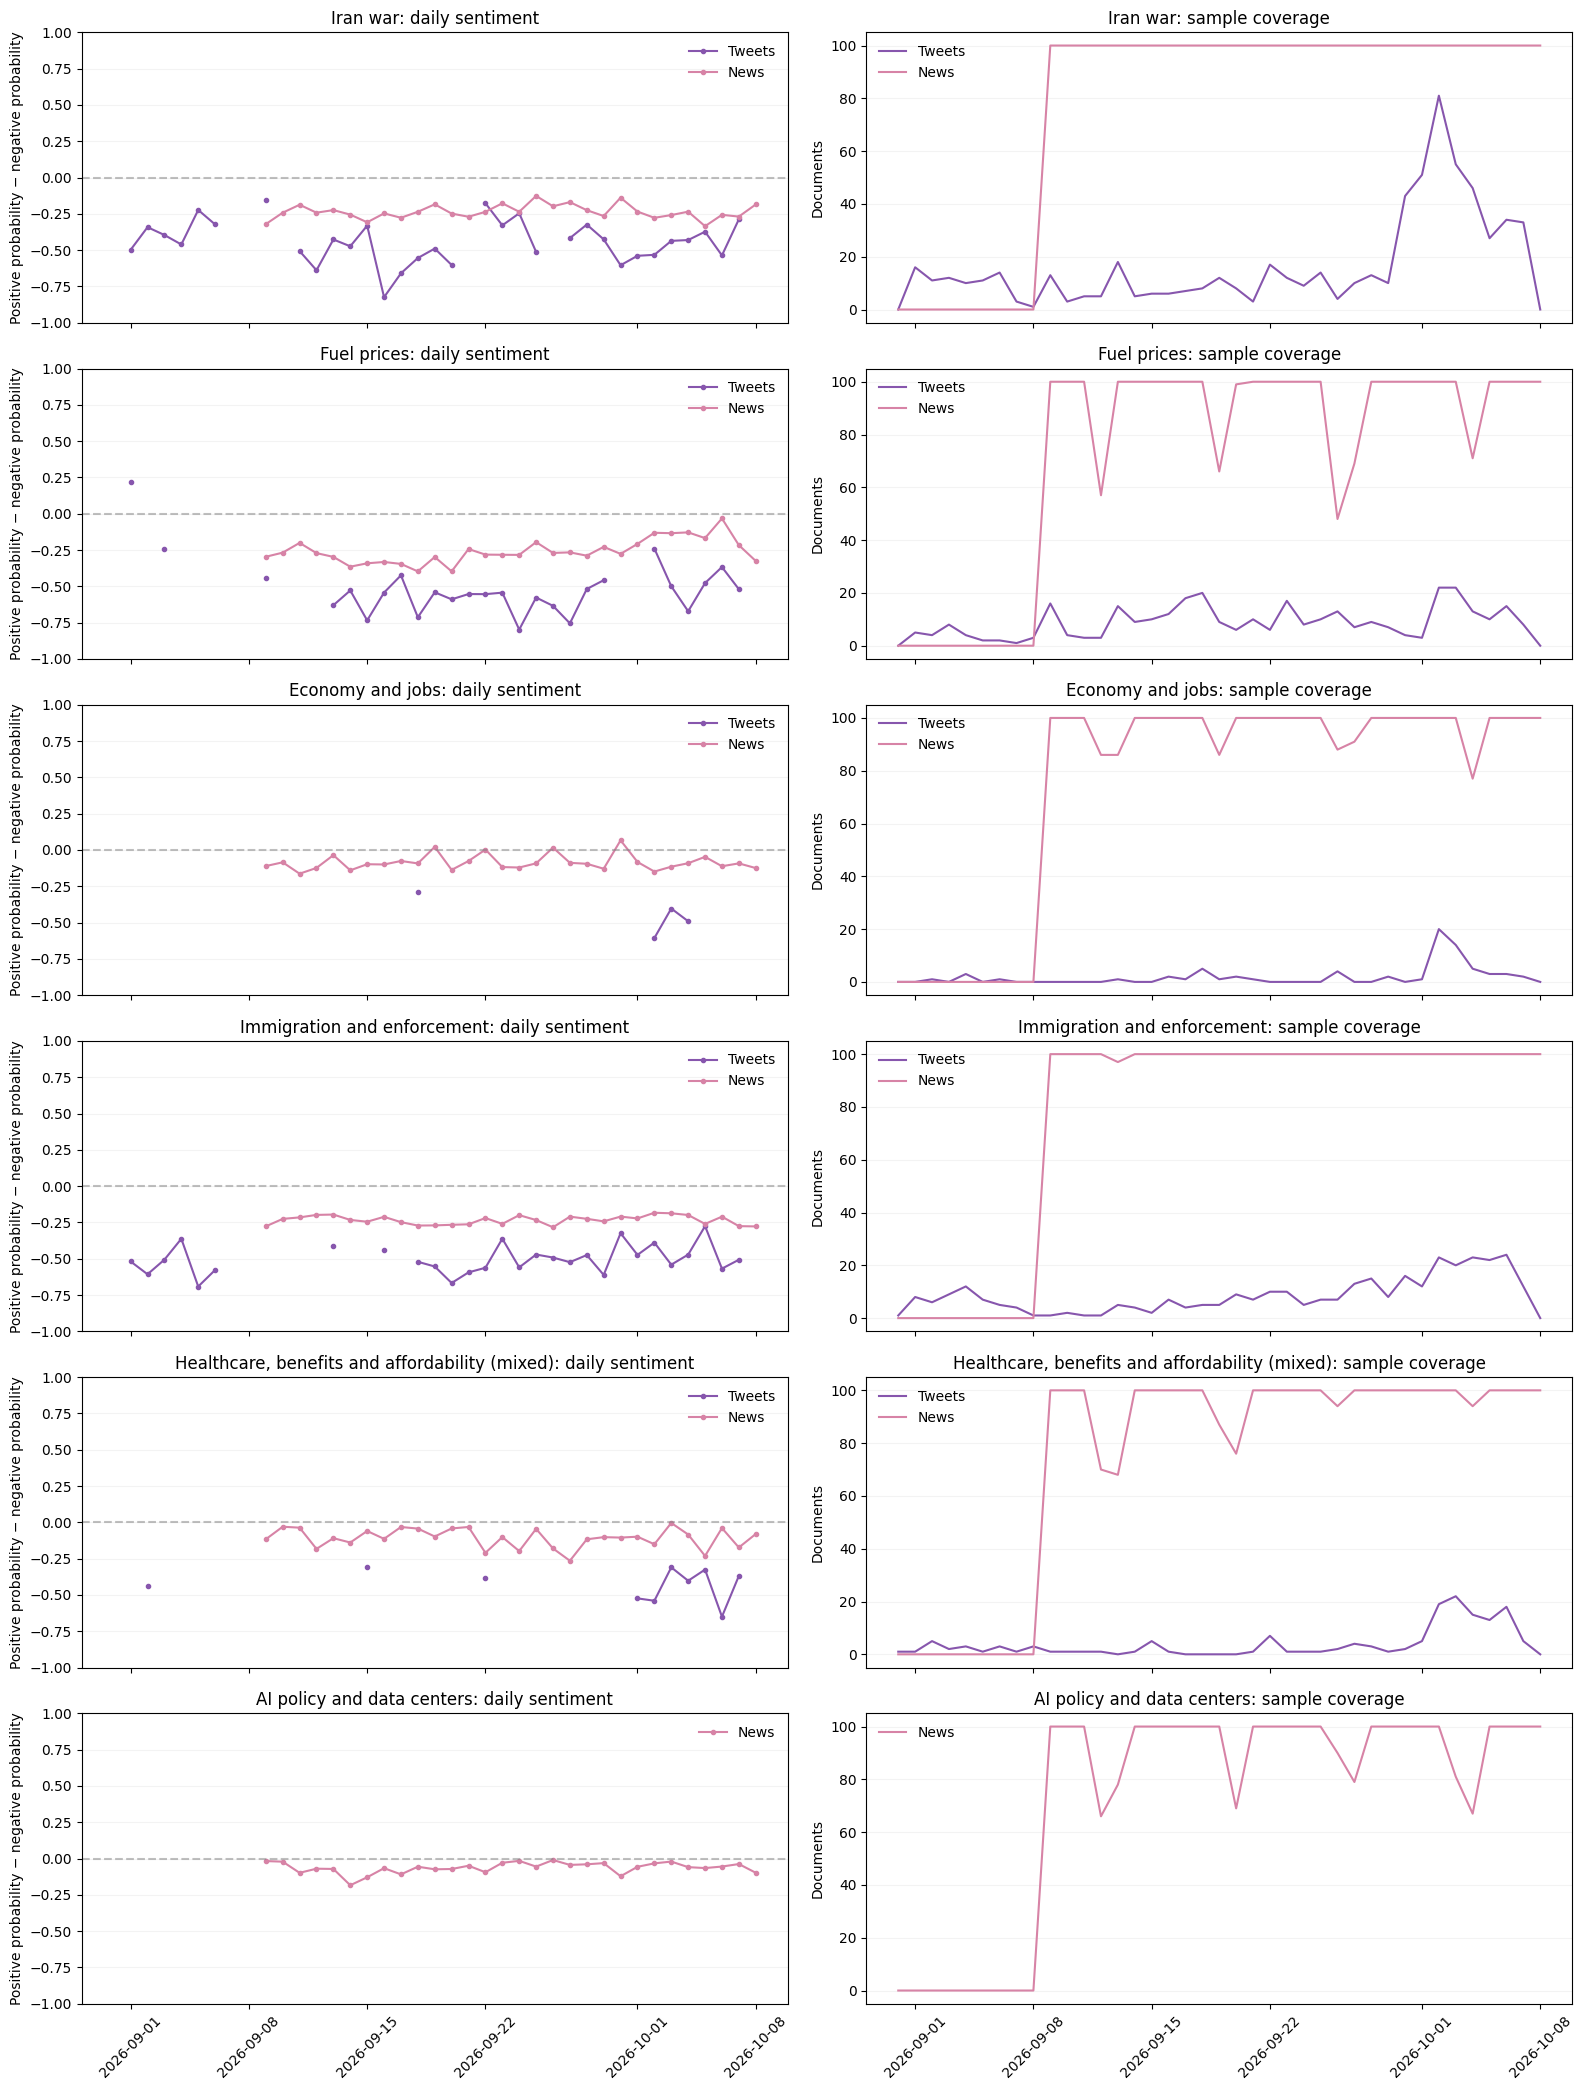

total_documents  \
source issue                                                             
News   AI policy and data centers                                 2830   
       Economy and jobs                                           2914   
       Fuel prices                                                2810   
       Healthcare, benefits and affordability (mixed)             2889   
       Immigration and enforcement                                2997   
       Iran war                                                   3000   
Tweets AI policy and data centers                                    0   
       Economy and jobs                                             72   
       Fuel prices                                                 338   
       Healthcare, benefits and affordability (mixed)              151   
       Immigration and enforcement                                 333   
       Iran war                                                    636   

                                                       usable_daily_indices  
source issue                                                                 
News   AI policy and data centers                                        30  
       Economy and jobs                                                  30  
       Fuel prices                                                       30  
       Healthcare, benefits and affordability (mixed)                    30  
       Immigration and enforcement                                       30  
       Iran war                                                          30  
Tweets AI policy and data centers                                         0  
       Economy and jobs                                                   4  
       Fuel prices                                                       26  
       Healthcare, benefits and affordability (mixed)                    10  
       Immigration and enforcement                                       28  
       Iran war                                                          32

In [55]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

SENTIMENT_DIR = Path(FOLDER) / "sentiment_outputs"
NEWS_DIR = Path(FOLDER) / "issue_news_supplement"
SENTIMENT_DIR.mkdir(parents=True, exist_ok=True)

MIN_DAILY_DOCUMENTS = 5

ISSUES = [
    "Iran war",
    "Fuel prices",
    "Economy and jobs",
    "Immigration and enforcement",
    "Healthcare, benefits and affordability (mixed)",
    "AI policy and data centers",
]

# Recover existing scores—no API calls or rescoring.
if "sentiment_documents" not in globals():
    sentiment_documents = pd.read_csv(
        SENTIMENT_DIR / "issue_documents_scored.csv"
    )

tweet_scored = sentiment_documents.loc[
    sentiment_documents["source"].eq("Tweets")
].copy()

if tweet_scored.empty:
    raise ValueError(
        "No saved tweet scores found in issue_documents_scored.csv."
    )

if "news_scored" not in globals():
    news_scored = pd.read_csv(
        NEWS_DIR / "all_issues_news_scored.csv"
    )

sentiment_documents = pd.concat(
    [tweet_scored, news_scored],
    ignore_index=True,
)

sentiment_documents["issue"] = sentiment_documents["issue"].replace({
    "Immigration": "Immigration and enforcement",
    "Healthcare": "Healthcare, benefits and affordability (mixed)",
    "AI and data centers": "AI policy and data centers",
})
sentiment_documents["date_ny"] = pd.to_datetime(
    sentiment_documents["date_ny"], errors="coerce"
).dt.normalize()
sentiment_documents["sentiment"] = pd.to_numeric(
    sentiment_documents["sentiment"], errors="coerce"
)
sentiment_documents = sentiment_documents.dropna(subset=["date_ny"])

daily_sentiment = (
    sentiment_documents.groupby(["source", "issue", "date_ny"])
    .agg(
        documents=("sentiment", "size"),
        scored_documents=("sentiment", "count"),
        mean_sentiment=("sentiment", "mean"),
        median_sentiment=("sentiment", "median"),
        negative_share=(
            "sentiment_label",
            lambda x: x.dropna().str.lower().eq("negative").mean(),
        ),
    )
)

calendar = pd.date_range(
    sentiment_documents["date_ny"].min(),
    sentiment_documents["date_ny"].max(),
    freq="D",
)
grid = pd.MultiIndex.from_product(
    [["Tweets", "News"], ISSUES, calendar],
    names=["source", "issue", "date_ny"],
)

daily_sentiment = daily_sentiment.reindex(grid).reset_index()

for column in ["documents", "scored_documents"]:
    daily_sentiment[column] = (
        daily_sentiment[column].fillna(0).astype(int)
    )

daily_sentiment["sentiment_index"] = (
    daily_sentiment["mean_sentiment"].where(
        daily_sentiment["scored_documents"] >= MIN_DAILY_DOCUMENTS
    )
)

fig_sentiment, axes = plt.subplots(
    len(ISSUES), 2,
    figsize=(16, 3.5 * len(ISSUES)),
    sharex=True,
    squeeze=False,
)

for row, issue in enumerate(ISSUES):
    for source, color in [
        ("Tweets", "#8756AD"),
        ("News", "#D783A6"),
    ]:
        subset = daily_sentiment.loc[
            daily_sentiment["issue"].eq(issue)
            & daily_sentiment["source"].eq(source)
        ]

        if subset["documents"].sum() == 0:
            continue

        axes[row, 0].plot(
            subset["date_ny"],
            subset["sentiment_index"],
            label=source,
            color=color,
            marker=".",
            linewidth=1.5,
        )
        axes[row, 1].plot(
            subset["date_ny"],
            subset["documents"],
            label=source,
            color=color,
            linewidth=1.5,
        )

    axes[row, 0].axhline(
        0, color="gray", linestyle="--", alpha=0.5
    )
    axes[row, 0].set_title(f"{issue}: daily sentiment")
    axes[row, 0].set_ylabel("Positive probability − negative probability")
    axes[row, 0].set_ylim(-1, 1)

    axes[row, 1].set_title(f"{issue}: sample coverage")
    axes[row, 1].set_ylabel("Documents")

    for ax in axes[row]:
        ax.grid(axis="y", alpha=0.15)
        ax.tick_params(axis="x", rotation=45)
        handles, labels = ax.get_legend_handles_labels()
        if handles:
            ax.legend(frameon=False)

fig_sentiment.tight_layout()
fig_sentiment.savefig(
    SENTIMENT_DIR / "daily_topic_sentiment.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

coverage_summary = (
    daily_sentiment.groupby(["source", "issue"])
    .agg(
        total_documents=("documents", "sum"),
        usable_daily_indices=("sentiment_index", "count"),
    )
)

daily_sentiment.to_csv(
    SENTIMENT_DIR / "daily_topic_sentiment.csv", index=False
)
sentiment_documents.to_csv(
    SENTIMENT_DIR / "issue_documents_scored.csv", index=False
)
coverage_summary.to_csv(
    SENTIMENT_DIR / "sentiment_coverage_summary.csv"
)

display(coverage_summary)

In [57]:
from pathlib import Path
import pandas as pd

market_daily = pd.read_csv(
    Path(FOLDER) / "prediction_market" / "polymarket_dem_sweep_daily.csv",
    parse_dates=["date_ny"],
)

display(market_daily.head())

,date_ny,dem_sweep_probability,last_observation_ny,observations,probability_change_pp
0,2026-09-01,0.505,2026-09-01 23:00:16-04:00,23,NaN
1,2026-09-02,0.505,2026-09-02 23:00:17-04:00,24,0.0
2,2026-09-03,0.495,2026-09-03 23:00:18-04:00,25,-1.0
3,2026-09-04,0.495,2026-09-04 23:00:18-04:00,24,0.0
4,2026-09-05,0.495,2026-09-05 23:00:15-04:00,24,0.0



LEVELS


,source,issue,paired_days,pearson_r,spearman_r,p_value,p_holm,status
0,News,AI policy and data centers,30,0.2207,0.2504,0.2413,1.0,Exploratory
3,News,Economy and jobs,30,0.1972,0.1181,0.2963,1.0,Exploratory
6,News,Fuel prices,30,0.3748,0.5637,0.0413,1.0,Exploratory
9,News,"Healthcare, benefits and affordability (mixed)",30,-0.1140,-0.1105,0.5487,1.0,Exploratory
12,News,Immigration and enforcement,30,-0.0235,0.1262,0.9021,1.0,Exploratory
15,News,Iran war,30,0.0768,-0.0392,0.6868,1.0,Exploratory
18,Tweets,AI policy and data centers,0,NaN,NaN,NaN,NaN,Too few days
21,Tweets,Economy and jobs,4,NaN,NaN,NaN,NaN,Too few days
24,Tweets,Fuel prices,24,0.1089,0.1503,0.6124,1.0,Exploratory
27,Tweets,"Healthcare, benefits and affordability (mixed)",9,NaN,NaN,NaN,NaN,Too few days



DAILY CHANGES


,source,issue,paired_days,pearson_r,spearman_r,p_value,p_holm,status
1,News,AI policy and data centers,29,0.2460,0.2127,0.1984,1.0,Exploratory
4,News,Economy and jobs,29,0.1224,0.0963,0.5269,1.0,Exploratory
7,News,Fuel prices,29,0.2430,0.2938,0.2039,1.0,Exploratory
10,News,"Healthcare, benefits and affordability (mixed)",29,0.1166,0.1136,0.5470,1.0,Exploratory
13,News,Immigration and enforcement,29,0.0180,0.1194,0.9260,1.0,Exploratory
16,News,Iran war,29,-0.0481,-0.0562,0.8044,1.0,Exploratory
19,Tweets,AI policy and data centers,0,NaN,NaN,NaN,NaN,Too few days
22,Tweets,Economy and jobs,2,NaN,NaN,NaN,NaN,Too few days
25,Tweets,Fuel prices,21,0.0442,0.0539,0.8491,1.0,Exploratory
28,Tweets,"Healthcare, benefits and affordability (mixed)",6,NaN,NaN,NaN,NaN,Too few days



PREVIOUS-DAY SENTIMENT


,source,issue,paired_days,pearson_r,spearman_r,p_value,p_holm,status
2,News,AI policy and data centers,29,-0.5421,-0.3670,0.0024,0.0644,Exploratory
5,News,Economy and jobs,29,-0.1466,-0.1403,0.4480,1.0000,Exploratory
8,News,Fuel prices,29,-0.3669,-0.3548,0.0502,1.0000,Exploratory
11,News,"Healthcare, benefits and affordability (mixed)",29,0.0876,0.1156,0.6514,1.0000,Exploratory
14,News,Immigration and enforcement,29,0.1048,0.1354,0.5885,1.0000,Exploratory
17,News,Iran war,29,-0.1777,-0.0999,0.3564,1.0000,Exploratory
20,Tweets,AI policy and data centers,0,NaN,NaN,NaN,NaN,Too few days
23,Tweets,Economy and jobs,4,NaN,NaN,NaN,NaN,Too few days
26,Tweets,Fuel prices,24,-0.1353,-0.1119,0.5285,1.0000,Exploratory
29,Tweets,"Healthcare, benefits and affordability (mixed)",9,NaN,NaN,NaN,NaN,Too few days


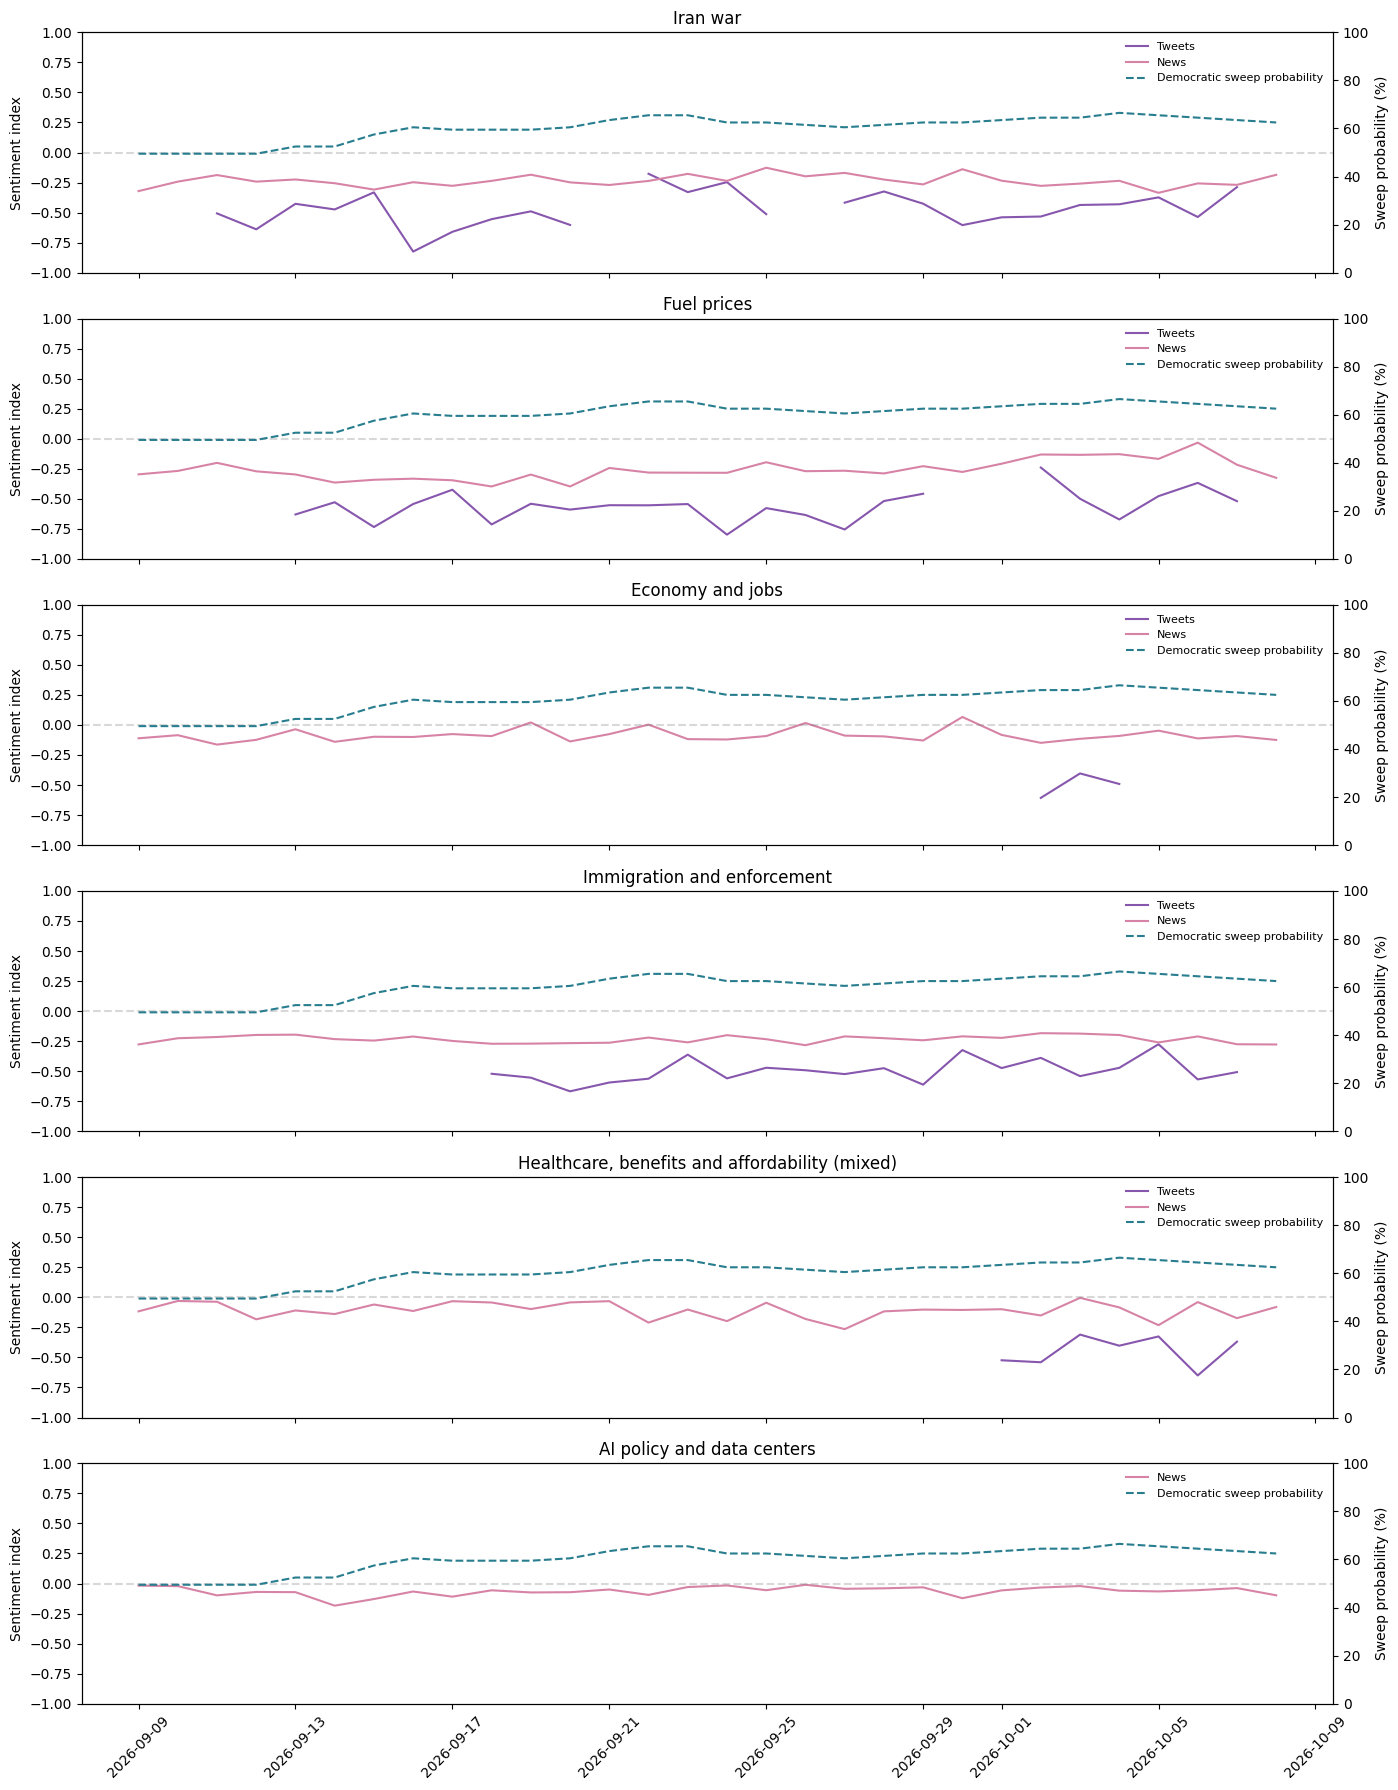

In [58]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.stats import pearsonr, spearmanr
from statsmodels.stats.multitest import multipletests

START = pd.Timestamp("2026-09-09")
END = pd.Timestamp("2026-10-08")
calendar = pd.date_range(START, END, freq="D")

OUTPUT_DIR = Path(FOLDER) / "sentiment_market_outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Reload sentiment output if needed.
if "daily_sentiment" not in globals():
    daily_sentiment = pd.read_csv(
        Path(FOLDER) / "sentiment_outputs" / "daily_topic_sentiment.csv"
    )

sent = daily_sentiment.copy()
sent["date_ny"] = pd.to_datetime(sent["date_ny"]).dt.normalize()

market = market_daily[
    ["date_ny", "dem_sweep_probability"]
].copy()
market["date_ny"] = pd.to_datetime(market["date_ny"]).dt.normalize()
market["dem_sweep_probability"] = pd.to_numeric(
    market["dem_sweep_probability"], errors="coerce"
)

if market["date_ny"].duplicated().any():
    raise ValueError("Market data contains duplicate dates.")
if not market["dem_sweep_probability"].dropna().between(0, 1).all():
    raise ValueError("Market probabilities must be between 0 and 1.")

# Calendar alignment prevents differences or lags from bridging gaps.
market = market.set_index("date_ny").reindex(calendar)
market.index.name = "date_ny"
market["probability_change_pp"] = (
    market["dem_sweep_probability"].diff() * 100
)

rows, panels = [], []

for (source, issue), group in sent.groupby(["source", "issue"]):
    if group["date_ny"].duplicated().any():
        raise ValueError(f"Duplicate sentiment dates: {source}, {issue}")

    panel = (
        group.set_index("date_ny")[["sentiment_index", "documents"]]
        .reindex(calendar)
        .join(market)
    )
    panel.index.name = "date_ny"
    panel["sentiment_change"] = panel["sentiment_index"].diff()
    panel["previous_day_sentiment"] = panel["sentiment_index"].shift(1)
    panel["source"] = source
    panel["issue"] = issue
    panels.append(panel.reset_index())

    for comparison, x, y in [
        ("Levels", "sentiment_index", "dem_sweep_probability"),
        ("Daily changes", "sentiment_change", "probability_change_pp"),
        (
            "Previous-day sentiment",
            "previous_day_sentiment",
            "probability_change_pp",
        ),
    ]:
        paired = panel[[x, y]].replace(
            [np.inf, -np.inf], np.nan
        ).dropna()

        result = {
            "source": source,
            "issue": issue,
            "comparison": comparison,
            "paired_days": len(paired),
            "pearson_r": np.nan,
            "spearman_r": np.nan,
            "p_value": np.nan,
            "status": "Too few days",
        }

        if len(paired) >= 10:
            if paired[x].nunique() > 1 and paired[y].nunique() > 1:
                r, p = pearsonr(paired[x], paired[y])
                rho, _ = spearmanr(paired[x], paired[y])
                result.update(
                    pearson_r=r,
                    spearman_r=rho,
                    p_value=p,
                    status="Exploratory",
                )
            else:
                result["status"] = "Constant series"

        rows.append(result)

sentiment_market_panel = pd.concat(panels, ignore_index=True)
correlation_results = pd.DataFrame(rows)

# Correct for testing multiple sources, issues, and comparisons.
correlation_results["p_holm"] = np.nan
valid = correlation_results["p_value"].notna()
if valid.any():
    correlation_results.loc[valid, "p_holm"] = multipletests(
        correlation_results.loc[valid, "p_value"], method="holm"
    )[1]

for comparison in ["Levels", "Daily changes", "Previous-day sentiment"]:
    print(f"\n{comparison.upper()}")
    display(
        correlation_results.loc[
            correlation_results["comparison"].eq(comparison),
            [
                "source", "issue", "paired_days",
                "pearson_r", "spearman_r",
                "p_value", "p_holm", "status",
            ],
        ].round(4)
    )

# Plot all issues against the same market probability.
issues = list(sent["issue"].dropna().unique())
fig, axes = plt.subplots(
    len(issues), 1,
    figsize=(14, 3 * len(issues)),
    sharex=True,
    squeeze=False,
)

for ax, issue in zip(axes.flat, issues):
    for source, color in [("Tweets", "#8756AD"), ("News", "#D783A6")]:
        subset = sentiment_market_panel.loc[
            sentiment_market_panel["issue"].eq(issue)
            & sentiment_market_panel["source"].eq(source)
        ]
        if subset["sentiment_index"].notna().any():
            ax.plot(
                subset["date_ny"], subset["sentiment_index"],
                label=source, color=color, linewidth=1.5,
            )

    ax.set_title(issue)
    ax.set_ylabel("Sentiment index")
    ax.set_ylim(-1, 1)
    ax.axhline(0, color="gray", linestyle="--", alpha=0.3)

    market_ax = ax.twinx()
    market_ax.plot(
        market.index, market["dem_sweep_probability"] * 100,
        color="#287D8E", linestyle="--",
        label="Democratic sweep probability",
    )
    market_ax.set_ylabel("Sweep probability (%)")
    market_ax.set_ylim(0, 100)

    handles, labels = ax.get_legend_handles_labels()
    h2, l2 = market_ax.get_legend_handles_labels()
    ax.legend(handles + h2, labels + l2, frameon=False, fontsize=8)

axes[-1, 0].tick_params(axis="x", rotation=45)
fig.tight_layout()
fig.savefig(
    OUTPUT_DIR / "sentiment_vs_sweep_probability.png",
    dpi=300, bbox_inches="tight",
)
plt.show()

sentiment_market_panel.to_csv(
    OUTPUT_DIR / "sentiment_polymarket_daily_panel.csv", index=False
)
correlation_results.to_csv(
    OUTPUT_DIR / "sentiment_polymarket_correlations.csv", index=False
)

In [59]:
%pip -q install yfinance

PERIOD PERFORMANCE


,period_return_pct,relative_wealth_vs_SPY_pct
HCA,10.90,9.48
GEO,-3.37,-4.60
FSLR,-16.13,-17.20
NVDA,2.22,0.92
XOM,4.88,3.54
LMT,-5.27,-6.48
Basket,-1.05,-2.31
SPY,1.29,0.00


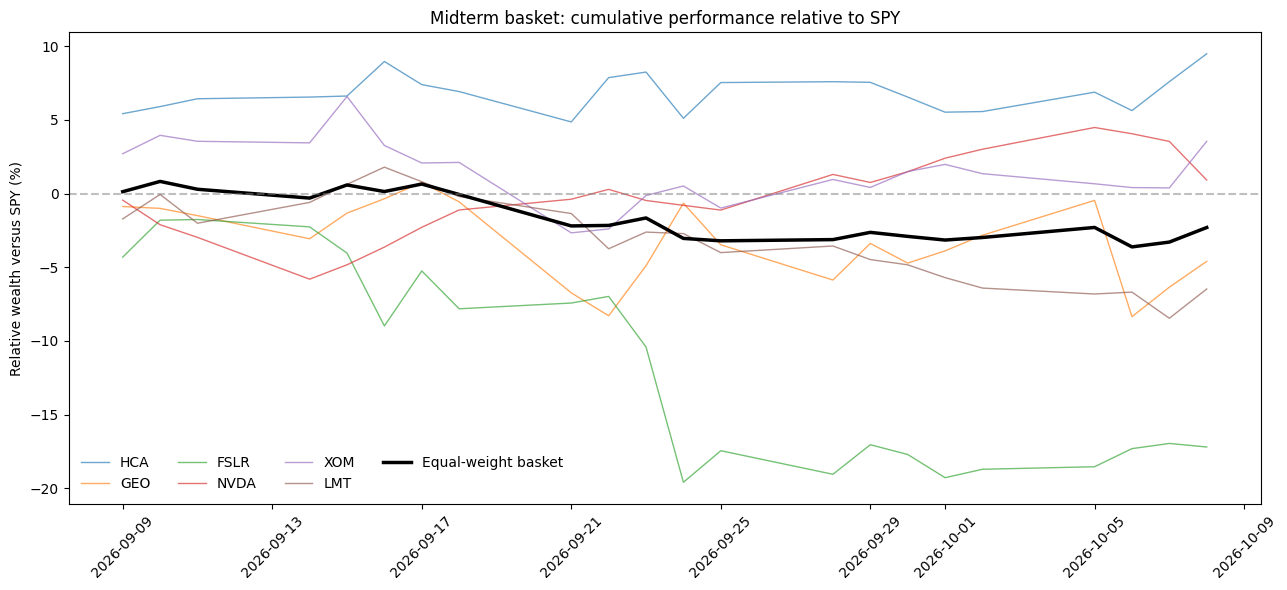

SENTIMENT VS BASKET MARKET-ADJUSTED RETURNS


,source,issue,equity,comparison,paired_days,pearson_r,p_value,p_holm
0,News,AI policy and data centers,Basket,Same-day sentiment,22,-0.0699,0.7573,1.0
1,News,AI policy and data centers,Basket,Same-day sentiment change,21,-0.0312,0.8934,1.0
2,News,AI policy and data centers,Basket,Previous-day sentiment,21,-0.0509,0.8266,1.0
6,News,Economy and jobs,Basket,Same-day sentiment,22,0.0239,0.9158,1.0
7,News,Economy and jobs,Basket,Same-day sentiment change,21,0.0157,0.9462,1.0
8,News,Economy and jobs,Basket,Previous-day sentiment,21,0.0059,0.9796,1.0
12,News,Fuel prices,Basket,Same-day sentiment,22,-0.1836,0.4134,1.0
13,News,Fuel prices,Basket,Same-day sentiment change,21,-0.4639,0.0342,1.0
14,News,Fuel prices,Basket,Previous-day sentiment,21,0.2633,0.2489,1.0
18,News,"Healthcare, benefits and affordability (mixed)",Basket,Same-day sentiment,22,-0.1425,0.5271,1.0


SENTIMENT VS MATCHED INDIVIDUAL EQUITIES


,source,issue,equity,comparison,paired_days,pearson_r,p_value,p_holm
3,News,AI policy and data centers,NVDA,Same-day sentiment,22,0.1714,0.4456,1.0000
4,News,AI policy and data centers,NVDA,Same-day sentiment change,21,0.4471,0.0422,1.0000
5,News,AI policy and data centers,NVDA,Previous-day sentiment,21,-0.3563,0.1129,1.0000
9,News,Economy and jobs,XOM,Same-day sentiment,22,-0.0259,0.9090,1.0000
10,News,Economy and jobs,XOM,Same-day sentiment change,21,-0.1182,0.6098,1.0000
11,News,Economy and jobs,XOM,Previous-day sentiment,21,0.1864,0.4186,1.0000
15,News,Fuel prices,XOM,Same-day sentiment,22,-0.2316,0.2997,1.0000
16,News,Fuel prices,XOM,Same-day sentiment change,21,-0.4390,0.0465,1.0000
17,News,Fuel prices,XOM,Previous-day sentiment,21,0.2038,0.3755,1.0000
21,News,"Healthcare, benefits and affordability (mixed)",HCA,Same-day sentiment,22,-0.2262,0.3113,1.0000


In [72]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
from pathlib import Path
from scipy.stats import pearsonr
from statsmodels.stats.multitest import multipletests

# TICKERS = ["HCA", "GEO", "FSLR", "NVDA", "XOM", "LMT"]
# BENCHMARK = "SPY"
# START = pd.Timestamp("2026-09-09")
# END = pd.Timestamp("2026-10-08")

# EQUITY_DIR = Path(FOLDER) / "equity_outputs"
# EQUITY_DIR.mkdir(parents=True, exist_ok=True)

prices.index = pd.to_datetime(prices.index).tz_localize(None).normalize()
prices = prices.sort_index().reindex(columns=TICKERS + [BENCHMARK])

if prices.empty or prices.isna().any().any():
    raise ValueError(
        "Missing price data. Inspect prices before constructing the basket."
    )

returns = prices.pct_change(fill_method=None)
returns = returns.loc[START:END].copy()

# Equal-weight basket, rebalanced daily.
returns["Basket"] = returns[TICKERS].mean(axis=1)
returns["Basket_excess_SPY"] = returns["Basket"] - returns[BENCHMARK]

for ticker in TICKERS:
    returns[f"{ticker}_excess_SPY"] = (
        returns[ticker] - returns[BENCHMARK]
    )

returns.index.name = "date_ny"

# Performance summaries.
summary = pd.DataFrame({
    "period_return_pct": (
        (1 + returns[TICKERS + ["Basket", BENCHMARK]]).prod() - 1
    ) * 100,
})

spy_growth = (1 + returns[BENCHMARK]).prod()
summary["relative_wealth_vs_SPY_pct"] = [
    (
        (1 + returns[name]).prod() / spy_growth - 1
    ) * 100
    for name in summary.index
]

print("PERIOD PERFORMANCE")
display(summary.round(2))

# Relative wealth is distinct from compounding daily return differences.
wealth = (1 + returns[TICKERS + ["Basket", BENCHMARK]]).cumprod()
relative_wealth = wealth.div(wealth[BENCHMARK], axis=0) - 1

fig, ax = plt.subplots(figsize=(13, 6))
for ticker in TICKERS:
    ax.plot(
        relative_wealth.index,
        relative_wealth[ticker] * 100,
        label=ticker,
        alpha=0.65,
        linewidth=1,
    )

ax.plot(
    relative_wealth.index,
    relative_wealth["Basket"] * 100,
    color="black",
    linewidth=2.5,
    label="Equal-weight basket",
)
ax.axhline(0, color="gray", linestyle="--", alpha=0.5)
ax.set_title("Midterm basket: cumulative performance relative to SPY")
ax.set_ylabel("Relative wealth versus SPY (%)")
ax.legend(ncol=4, frameon=False)
ax.tick_params(axis="x", rotation=45)
fig.tight_layout()
fig.savefig(
    EQUITY_DIR / "midterm_basket_relative_performance.png",
    dpi=300, bbox_inches="tight",
)
plt.show()

# Existing sentiment—no recollection or rescoring.
sent = daily_sentiment.copy()
sent["date_ny"] = pd.to_datetime(sent["date_ny"]).dt.normalize()
calendar = pd.date_range(START, END, freq="D")

# Preselected company/issue comparisons, plus every issue vs the basket.
ISSUE_EQUITIES = {
    "Iran war": ["LMT"],
    "Fuel prices": ["XOM"],
    "Economy and jobs": ["XOM"],
    "Immigration and enforcement": ["GEO"],
    "Healthcare, benefits and affordability (mixed)": ["HCA"],
    "AI policy and data centers": ["NVDA"],
}
# FSLR remains in the basket; existing fuel-price sentiment is not
# automatically interpreted as sentiment toward solar incentives.

rows = []
panels = []

for (source, issue), group in sent.groupby(["source", "issue"]):
    s = (
        group.set_index("date_ny")["sentiment_index"]
        .reindex(calendar)
    )

    panel = pd.DataFrame({
        "sentiment_index": s,
        "sentiment_change": s.diff(),
        # Yesterday means the preceding calendar day, including weekends.
        "previous_day_sentiment": s.shift(1),
    }).join(returns)

    panel["source"] = source
    panel["issue"] = issue
    panel.index.name = "date_ny"
    panels.append(panel.reset_index())

    targets = ["Basket"] + ISSUE_EQUITIES.get(issue, [])

    for target in targets:
        return_column = (
            "Basket_excess_SPY"
            if target == "Basket"
            else f"{target}_excess_SPY"
        )

        for comparison, sentiment_column in [
            ("Same-day sentiment", "sentiment_index"),
            ("Same-day sentiment change", "sentiment_change"),
            ("Previous-day sentiment", "previous_day_sentiment"),
        ]:
            paired = panel[
                [sentiment_column, return_column]
            ].replace([np.inf, -np.inf], np.nan).dropna()

            result = {
                "source": source,
                "issue": issue,
                "equity": target,
                "comparison": comparison,
                "paired_days": len(paired),
                "pearson_r": np.nan,
                "p_value": np.nan,
            }

            if (
                len(paired) >= 10
                and paired[sentiment_column].nunique() > 1
                and paired[return_column].nunique() > 1
            ):
                r, p = pearsonr(
                    paired[sentiment_column], paired[return_column]
                )
                result.update(pearson_r=r, p_value=p)

            rows.append(result)

equity_correlations = pd.DataFrame(rows)
equity_correlations["p_holm"] = np.nan

valid = equity_correlations["p_value"].notna()
if valid.any():
    equity_correlations.loc[valid, "p_holm"] = multipletests(
        equity_correlations.loc[valid, "p_value"],
        method="holm",
    )[1]

equity_sentiment_panel = pd.concat(panels, ignore_index=True)

print("SENTIMENT VS BASKET MARKET-ADJUSTED RETURNS")
display(
    equity_correlations.loc[
        equity_correlations["equity"].eq("Basket")
    ].round(4)
)

print("SENTIMENT VS MATCHED INDIVIDUAL EQUITIES")
display(
    equity_correlations.loc[
        equity_correlations["equity"].ne("Basket")
    ].round(4)
)

prices.to_csv(EQUITY_DIR / "adjusted_prices.csv")
returns.to_csv(EQUITY_DIR / "daily_equity_returns.csv")
summary.to_csv(EQUITY_DIR / "equity_performance_summary.csv")
equity_correlations.to_csv(
    EQUITY_DIR / "sentiment_equity_correlations.csv", index=False
)
equity_sentiment_panel.to_csv(
    EQUITY_DIR / "sentiment_equity_panel.csv", index=False
)

In [68]:
import subprocess
import sys
from pathlib import Path

PACKAGE_DIR = "/content/equity_packages_pinned"
PRICE_FILE = Path(FOLDER) / "equity_outputs" / "adjusted_prices.csv"
PRICE_FILE.parent.mkdir(parents=True, exist_ok=True)

subprocess.run(
    [
        sys.executable, "-m", "pip", "install",
        "--quiet", "--upgrade", "--target", PACKAGE_DIR,
        "yfinance==0.2.66",
        "curl_cffi==0.13.0",
    ],
    check=True,
)

script = """
import sys
sys.path.insert(0, sys.argv[1])

import yfinance as yf
import curl_cffi
from curl_cffi import requests

print("Using:", yf.__version__, curl_cffi.__version__, flush=True)

session = requests.Session(impersonate="chrome")
tickers = ["HCA", "GEO", "FSLR", "NVDA", "XOM", "LMT", "SPY"]

raw = yf.download(
    tickers,
    start="2026-09-01",
    end="2026-10-09",
    auto_adjust=True,
    threads=False,
    progress=False,
    session=session,
)

prices = raw["Close"].reindex(columns=tickers)
if prices.empty or prices.isna().any().any():
    raise RuntimeError("Incomplete download; existing file preserved.")

prices.to_csv(sys.argv[2])
print(f"Saved {len(prices)} dates.", flush=True)
"""

subprocess.run(
    [sys.executable, "-c", script, PACKAGE_DIR, str(PRICE_FILE)],
    check=True,
)

CompletedProcess(args=['/usr/bin/python3', '-c', '\nimport sys\nsys.path.insert(0, sys.argv[1])\n\nimport yfinance as yf\nimport curl_cffi\nfrom curl_cffi import requests\n\nprint("Using:", yf.__version__, curl_cffi.__version__, flush=True)\n\nsession = requests.Session(impersonate="chrome")\ntickers = ["HCA", "GEO", "FSLR", "NVDA", "XOM", "LMT", "SPY"]\n\nraw = yf.download(\n    tickers,\n    start="2026-09-01",\n    end="2026-10-09",\n    auto_adjust=True,\n    threads=False,\n    progress=False,\n    session=session,\n)\n\nprices = raw["Close"].reindex(columns=tickers)\nif prices.empty or prices.isna().any().any():\n    raise RuntimeError("Incomplete download; existing file preserved.")\n\nprices.to_csv(sys.argv[2])\nprint(f"Saved {len(prices)} dates.", flush=True)\n', '/content/equity_packages_pinned', '/content/drive/MyDrive/midterm-tweets/equity_outputs/adjusted_prices.csv'], returncode=0)

In [71]:
prices = pd.read_csv(
    Path(FOLDER) / "equity_outputs" / "adjusted_prices.csv",
    index_col=0,
    parse_dates=True,
)